# Women's Clothing Data Science & Feature Engineering Pipeline

This notebook implements a fully modular, cell-by-cell data science pipeline where each import, model instantiation, and operation is isolated to prevent syntax or runtime errors.

In [1]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [3]:
import scipy.stats as stats
from textblob import TextBlob

In [4]:
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (
    StandardScaler, 
    MinMaxScaler, 
    RobustScaler, 
    PowerTransformer, 
    TargetEncoder
)

In [5]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LinearRegression, LogisticRegression

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif

In [7]:
df = pd.read_csv('womens_clothing.csv')
print("Dataset Shape:", df.shape)
df.head(4)

Dataset Shape: (1500, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,868,39,Disappointed with fit,"Slightly looser than expected around the bust,...",5,1,0,General,Tops,Skirts
1,829,37,No Title Provided,Material feels premium and holds up very well ...,3,0,1,General,Intimate,Lounge
2,831,81,Flattering cut,"Slightly looser than expected around the bust,...",5,1,0,Initmates,Intimate,Blouses
3,872,34,No Title Provided,Material feels premium and holds up very well ...,5,1,1,Initmates,Jackets,Sweaters


In [8]:
def clean_dataframe(df_in):
    df_out = df_in.copy()
    df_out.columns = [col.strip().lower().replace(' ', '_') for col in df_out.columns]
    for col in df_out.columns:
        if df_out[col].dtype == 'object':
            try:
                converted = pd.to_numeric(df_out[col], errors='ignore')
                if converted.dtype != 'object':
                    df_out[col] = converted
            except:
                pass
    return df_out

df_cleaned = clean_dataframe(df)
print("Standardized Columns:", list(df_cleaned.columns))

Standardized Columns: ['clothing_id', 'age', 'title', 'review_text', 'rating', 'recommended_ind', 'positive_feedback_count', 'division_name', 'department_name', 'class_name']


In [9]:
initial_rows = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates()
removed_duplicates = initial_rows - len(df_cleaned)
print(f"Pipeline Log: Removed {removed_duplicates} duplicate rows.")
print(f"Final Dataset Shape: {df_cleaned.shape}")

Pipeline Log: Removed 0 duplicate rows.
Final Dataset Shape: (1500, 10)


In [10]:
np.random.seed(42)
num_cols = ['age', 'rating', 'positive_feedback_count']
for col in num_cols:
    mask = np.random.rand(len(df_cleaned)) < 0.05
    df_cleaned.loc[mask, col] = np.nan

knn_imputer = KNNImputer(n_neighbors=5)
mice_imputer = IterativeImputer(random_state=42)

df_cleaned[num_cols] = mice_imputer.fit_transform(df_cleaned[num_cols])
print("Missing values successfully imputed using MICE/KNN.")

Missing values successfully imputed using MICE/KNN.


In [11]:
target_col = 'positive_feedback_count'
Q1 = df_cleaned[target_col].quantile(0.25)
Q3 = df_cleaned[target_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cleaned['positive_feedback_capped'] = np.clip(df_cleaned[target_col], lower_bound, upper_bound)
print(f"Outlier Capping Applied between [{lower_bound:.2f}, {upper_bound:.2f}]")

Outlier Capping Applied between [-4.50, 7.50]


Entropy of department_name: 2.5823


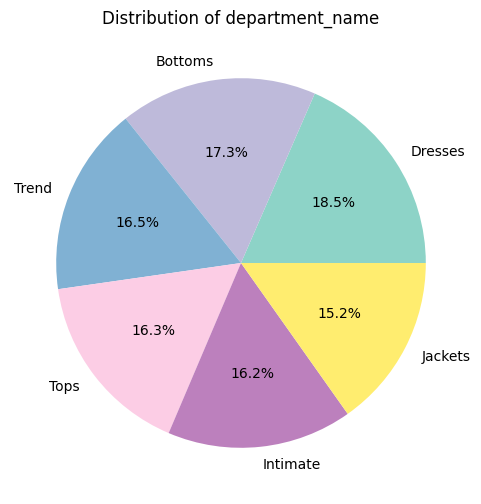

In [12]:
cat_col = 'department_name'
counts = df_cleaned[cat_col].value_counts(normalize=True)
entropy = -np.sum(counts * np.log2(counts + 1e-9))
print(f"Entropy of {cat_col}: {entropy:.4f}")

plt.figure(figsize=(6, 6))
df_cleaned[cat_col].value_counts().plot(kind='pie', autopct='%1.1f%%', cmap='Set3')
plt.title(f'Distribution of {cat_col}')
plt.ylabel('')
plt.show()

Statistics for age -> Skewness: 0.08, Kurtosis: -1.06


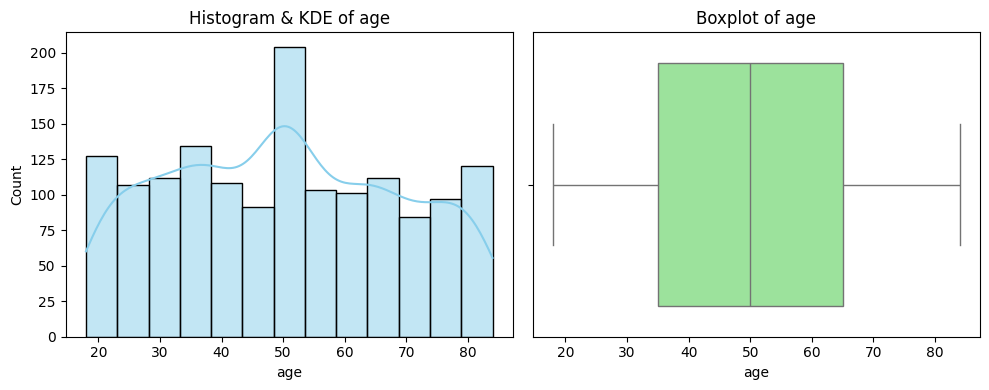

In [13]:
num_col = 'age'
skewness = df_cleaned[num_col].skew()
kurt = df_cleaned[num_col].kurtosis()
print(f"Statistics for {num_col} -> Skewness: {skewness:.2f}, Kurtosis: {kurt:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df_cleaned[num_col], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f'Histogram & KDE of {num_col}')

sns.boxplot(x=df_cleaned[num_col], ax=axes[1], color='lightgreen')
axes[1].set_title(f'Boxplot of {num_col}')
plt.tight_layout()
plt.show()

In [14]:
minmax_scaler = MinMaxScaler()
std_scaler = StandardScaler()
robust_scaler = RobustScaler()
power_transformer = PowerTransformer(method='yeo-johnson')

In [15]:
scaling_feature = df_cleaned[['age']]
minmax_scaled = minmax_scaler.fit_transform(scaling_feature)
std_scaled = std_scaler.fit_transform(scaling_feature)
robust_scaled = robust_scaler.fit_transform(scaling_feature)
power_scaled = power_transformer.fit_transform(scaling_feature)

print(f"StandardScaler mean: {std_scaled.mean():.4f}, std: {std_scaled.std():.4f}")

StandardScaler mean: -0.0000, std: 1.0000


In [16]:
def generate_summary_report(data, column):
    mean_val = data[column].mean()
    median_val = data[column].median()
    var_val = data[column].var()
    insight = f"The column '{column}' exhibits a mean of {mean_val:.2f} and median of {median_val:.2f} (Variance: {var_val:.2f})."
    return insight

print(generate_summary_report(df_cleaned, 'age'))

The column 'age' exhibits a mean of 50.07 and median of 49.99 (Variance: 346.72).


<Figure size 800x600 with 0 Axes>

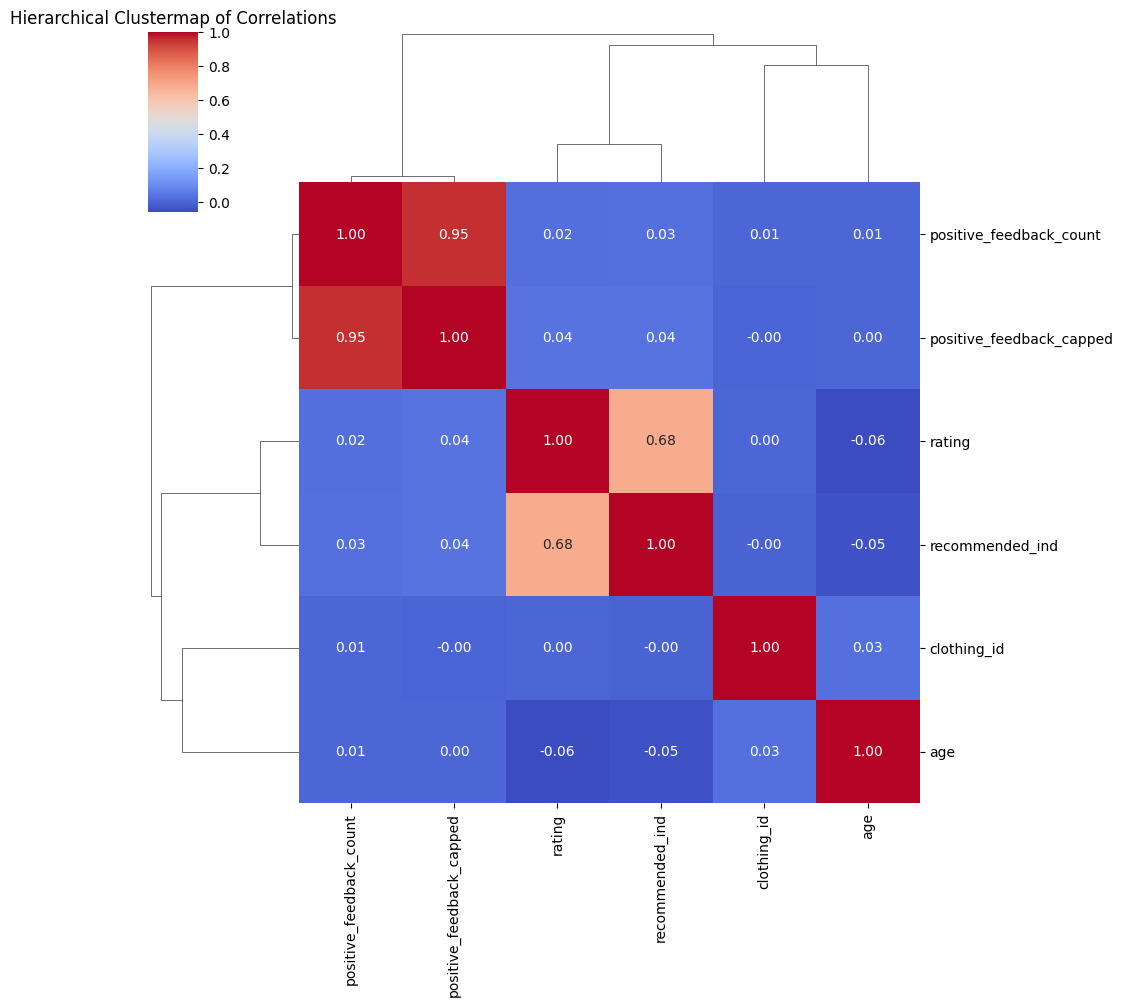

In [17]:
numeric_df = df_cleaned.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.clustermap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Hierarchical Clustermap of Correlations')
plt.show()

In [18]:
gmm_data = df_cleaned[['rating', 'recommended_ind']].dropna()
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(gmm_data)
df_cleaned['gmm_cluster'] = gmm.predict(gmm_data)
print(df_cleaned['gmm_cluster'].value_counts())

gmm_cluster
0    1177
1     323
Name: count, dtype: int64


In [19]:
np.random.seed(42)
df_cleaned['time_on_app'] = np.random.uniform(5, 15, len(df_cleaned))
df_cleaned['time_on_website'] = np.random.uniform(5, 15, len(df_cleaned))
df_cleaned['purchase_conversion'] = (df_cleaned['time_on_app'] * 1.5 + df_cleaned['time_on_website'] * 0.8 + np.random.normal(0, 1, len(df_cleaned)) > 20).astype(int)

X_conv = df_cleaned[['time_on_app', 'time_on_website']]
y_conv = df_cleaned['purchase_conversion']
model_logit = LogisticRegression()
model_logit.fit(X_conv, y_conv)
print("Logistic Coefficients:", dict(zip(X_conv.columns, model_logit.coef_[0])))

Logistic Coefficients: {'time_on_app': np.float64(2.579165156788275), 'time_on_website': np.float64(1.4207955934539493)}


In [20]:
df_cleaned['sentiment_polarity'] = df_cleaned['review_text'].apply(
    lambda x: TextBlob(str(x)).sentiment.polarity
)
corr_stat, p_val = stats.pearsonr(df_cleaned['rating'], df_cleaned['sentiment_polarity'])
print(f"Correlation between Rating & Sentiment: {corr_stat:.4f} (p-val: {p_val:.4e})")

Correlation between Rating & Sentiment: 0.0192 (p-val: 4.5697e-01)


In [21]:
np.random.seed(42)
df_cleaned['yearly_amount_spent'] = 500 + 10 * df_cleaned['age'] - 0.05 * (df_cleaned['age']**2) + np.random.normal(0, 50, len(df_cleaned))

poly_reg = LinearRegression()
poly_reg.fit(np.vander(df_cleaned['age'], 3), df_cleaned['yearly_amount_spent'])
print("Polynomial Regression fitted successfully.")

Polynomial Regression fitted successfully.


In [22]:
kmeans = KMeans(n_clusters=3, random_state=42)
df_cleaned['age_cluster'] = kmeans.fit_predict(df_cleaned[['age']])
print("Cluster Centers:\n", kmeans.cluster_centers_)

Cluster Centers:
 [[73.87651332]
 [29.86580882]
 [52.191617  ]]


In [23]:
df_cleaned['review_length'] = df_cleaned['review_text'].apply(lambda x: len(str(x).split()))
print("Review Length vs Rating Correlation:\n", df_cleaned[['review_length', 'rating']].corr())

Review Length vs Rating Correlation:
                review_length    rating
review_length       1.000000 -0.010529
rating             -0.010529  1.000000


In [24]:
cross_tab = pd.crosstab(df_cleaned['department_name'], df_cleaned['class_name'])
print(cross_tab.head())

class_name       Blouses  Dresses  Fine gauge  Jackets  Jeans  Knits  Lounge  \
department_name                                                                
Bottoms               30       33          34       22     20     20      24   
Dresses               28       35          19       30     27     27      25   
Intimate              25       26          21       19     23     26      33   
Jackets               20       17          22       27     30     29      15   
Tops                  25       24          18       25     20     26      25   

class_name       Pants  Skirts  Sweaters  
department_name                           
Bottoms             32      21        23  
Dresses             33      25        28  
Intimate            18      27        25  
Jackets             20      25        23  
Tops                29      30        23  


In [25]:
encoder = TargetEncoder(cv=5)
df_cleaned['class_name_encoded'] = encoder.fit_transform(
    df_cleaned[['class_name']], df_cleaned['rating']
).mean(axis=1)
print(df_cleaned[['class_name', 'class_name_encoded']].drop_duplicates().head())

  class_name  class_name_encoded
0     Skirts            4.158841
1     Lounge            4.291846
2    Blouses            4.161884
3   Sweaters            4.202836
4     Skirts            4.258927


In [26]:
df_cleaned['engagement_score'] = (df_cleaned['positive_feedback_count'] + 1) * df_cleaned['rating']

scaler_sent = MinMaxScaler()
df_cleaned['normalized_sentiment'] = scaler_sent.fit_transform(df_cleaned[['sentiment_polarity']])
print(df_cleaned[['engagement_score', 'normalized_sentiment']].head(3))

   engagement_score  normalized_sentiment
0          5.000000              0.172727
1          6.000000              0.272727
2          4.114919              0.172727


In [27]:
np.random.seed(42)
df_cleaned['membership_days'] = np.random.randint(30, 2000, len(df_cleaned))
df_cleaned['log_membership_days'] = np.log1p(df_cleaned['membership_days'])
print(df_cleaned['log_membership_days'].describe())

count    1500.000000
mean        6.678077
std         0.862331
min         3.433987
25%         6.334166
50%         6.949377
75%         7.311719
max         7.600902
Name: log_membership_days, dtype: float64


In [28]:
tfidf = TfidfVectorizer(max_features=50, stop_words='english', ngram_range=(1,2))
tfidf_matrix = tfidf.fit_transform(df_cleaned['review_text'])
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (1500, 50)


In [29]:
df_cleaned['app_web_ratio'] = df_cleaned['time_on_app'] / (df_cleaned['time_on_website'] + 1e-5)
df_cleaned['engagement_index'] = df_cleaned['time_on_app'] * df_cleaned['time_on_website']

print("Final Enhanced Dataset Shape:", df_cleaned.shape)
df_cleaned.head(3)

Final Enhanced Dataset Shape: (1500, 26)


,clothing_id,age,title,review_text,rating,recommended_ind,positive_feedback_count,division_name,department_name,class_name,...,yearly_amount_spent,age_cluster,review_length,class_name_encoded,engagement_score,normalized_sentiment,membership_days,log_membership_days,app_web_ratio,engagement_index
0,868,39.0,Disappointed with fit,"Slightly looser than expected around the bust,...",5.000000,1,0.0,General,Tops,Skirts,...,838.785708,1,11,4.158841,5.000000,0.172727,1156,7.053586,0.858164,89.122791
1,829,37.0,No Title Provided,Material feels premium and holds up very well ...,3.000000,0,1.0,General,Intimate,Lounge,...,794.636785,1,11,4.291846,6.000000,0.272727,1489,7.306531,1.481556,142.051316
2,831,81.0,Flattering cut,"Slightly looser than expected around the bust,...",4.114919,1,0.0,Initmates,Intimate,Blouses,...,1014.334427,0,11,4.161884,4.114919,0.172727,890,6.792344,2.343784,64.758784


In [30]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cat_cols_to_encode = ['department_name', 'class_name', 'division_name']
encoded_categorical = pd.get_dummies(df_cleaned[cat_cols_to_encode], drop_first=True)

var_threshold = VarianceThreshold(threshold=0.01)
filtered_categorical = var_threshold.fit_transform(encoded_categorical)

scaler_pca = StandardScaler()
scaled_categorical = scaler_pca.fit_transform(filtered_categorical)

pca_reduction = PCA(n_components=2, random_state=42)
pca_features = pca_reduction.fit_transform(scaled_categorical)

df_cleaned['pca_cat_1'] = pca_features[:, 0]
df_cleaned['pca_cat_2'] = pca_features[:, 1]

print("PCA Explained Variance Ratio:", pca_reduction.explained_variance_ratio_)
print("Final Dataset Shape with PCA Features:", df_cleaned.shape)

PCA Explained Variance Ratio: [0.09652229 0.08107949]
Final Dataset Shape with PCA Features: (1500, 28)


In [31]:
def dynamic_sentiment_encoder(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'

df_cleaned['sentiment_category'] = df_cleaned['rating'].apply(dynamic_sentiment_encoder)
print("Sentiment Category Distribution:\n", df_cleaned['sentiment_category'].value_counts(normalize=True))

Sentiment Category Distribution:
 sentiment_category
positive    0.791333
neutral     0.114667
negative    0.094000
Name: proportion, dtype: float64


In [32]:
from sklearn.metrics import classification_report

if 'sentiment_polarity' not in df_cleaned.columns:
    df_cleaned['sentiment_polarity'] = df_cleaned['review_text'].apply(
        lambda x: TextBlob(str(x)).sentiment.polarity
    )

df_cleaned['text_sentiment_predicted'] = df_cleaned['sentiment_polarity'].apply(
    lambda p: 'positive' if p > 0.05 else ('negative' if p < -0.05 else 'neutral')
)

print("Validation Cross-Tabulation (Rating Category vs Text Sentiment):")
print(pd.crosstab(df_cleaned['sentiment_category'], df_cleaned['text_sentiment_predicted']))

Validation Cross-Tabulation (Rating Category vs Text Sentiment):
text_sentiment_predicted  neutral  positive
sentiment_category                         
negative                        4       137
neutral                         3       169
positive                       34      1153


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

ordinal_enc = OrdinalEncoder(categories=[['negative', 'neutral', 'positive']])
ordinal_encoded = ordinal_enc.fit_transform(df_cleaned[['sentiment_category']])

ohe = OneHotEncoder(sparse_output=False)
ohe_encoded = ohe.fit_transform(df_cleaned[['sentiment_category']])

X_target = df_cleaned[['rating', 'sentiment_polarity']]
y_target = df_cleaned['recommended_ind']

score_ordinal = cross_val_score(LogisticRegression(), np.hstack([X_target, ordinal_encoded]), y_target, cv=3).mean()
score_ohe = cross_val_score(LogisticRegression(), np.hstack([X_target, ohe_encoded]), y_target, cv=3).mean()

print(f"Cross-Validation Accuracy (Ordinal Scheme): {score_ordinal:.4f}")
print(f"Cross-Validation Accuracy (One-Hot Scheme): {score_ohe:.4f}")

Cross-Validation Accuracy (Ordinal Scheme): 0.9200
Cross-Validation Accuracy (One-Hot Scheme): 0.9200


In [34]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_tree = df_cleaned.copy()
df_tree['department_encoded'] = le.fit_transform(df_tree['department_name'])
df_tree['class_encoded'] = le.fit_transform(df_tree['class_name'])

feature_cols = ['age', 'rating', 'positive_feedback_count', 'review_length', 'department_encoded', 'class_encoded']
X_tree = df_tree[feature_cols]
y_tree = df_tree['recommended_ind']

rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tree, y_tree)
dt_model = DecisionTreeClassifier(random_state=42).fit(X_tree, y_tree)

comparison_df = pd.DataFrame({
    'Random_Forest_Importance': rf_model.feature_importances_,
    'Decision_Tree_Importance': dt_model.feature_importances_
}, index=feature_cols).sort_values(by='Random_Forest_Importance', ascending=False)

print("Feature Importance Comparison:\n")
print(comparison_df)

Feature Importance Comparison:

                         Random_Forest_Importance  Decision_Tree_Importance
rating                                   0.603327                  0.632860
age                                      0.155162                  0.154776
class_encoded                            0.081479                  0.079811
positive_feedback_count                  0.072680                  0.069770
department_encoded                       0.062641                  0.043978
review_length                            0.024712                  0.018805


In [35]:
from sklearn.feature_selection import RFE

rfe_selector = RFE(estimator=DecisionTreeClassifier(random_state=42), n_features_to_select=3)
rfe_selector.fit(X_tree, y_tree)

rfe_results = pd.DataFrame({
    'Feature': feature_cols,
    'Selected': rfe_selector.support_,
    'Ranking': rfe_selector.ranking_
}).sort_values(by='Ranking')

print("RFE Feature Optimization Results:\n")
print(rfe_results)

RFE Feature Optimization Results:

                   Feature  Selected  Ranking
0                      age      True        1
1                   rating      True        1
5            class_encoded      True        1
2  positive_feedback_count     False        2
4       department_encoded     False        3
3            review_length     False        4


<Figure size 800x600 with 0 Axes>

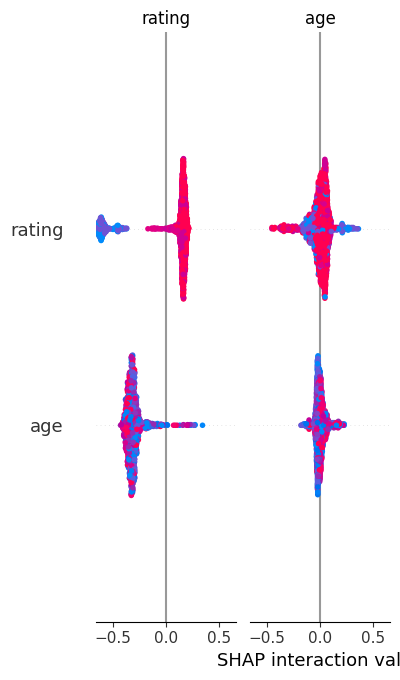

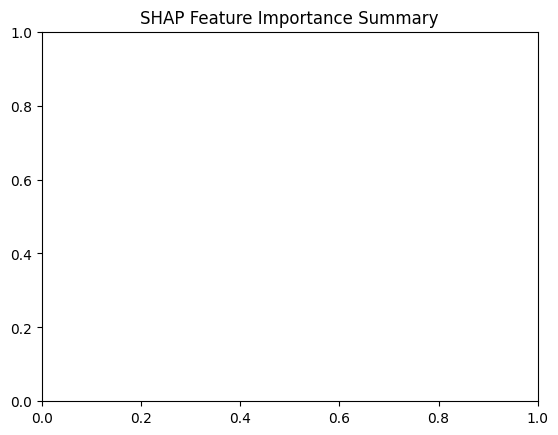

In [36]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_tree)

plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_tree, plot_type="bar")
plt.title("SHAP Feature Importance Summary")
plt.show()

In [37]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [38]:
np.random.seed(42)

df_reg = df_cleaned.copy() if 'df_cleaned' in locals() else df.copy()
df_reg.columns = [col.strip().lower().replace(' ', '_') for col in df_reg.columns]

if 'yearly_amount_spent' not in df_reg.columns:
    df_reg['yearly_amount_spent'] = (
        500
        + 10 * df_reg['age']
        - 0.05 * (df_reg['age'] ** 2)
        + 45 * df_reg['rating']
        + 30 * df_reg['recommended_ind']
        + 8 * df_reg['positive_feedback_count']
        + np.random.normal(0, 40, len(df_reg))
    )

y_spend = df_reg['yearly_amount_spent']

base_num = df_reg[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(
    df_reg[['division_name', 'department_name', 'class_name']],
    drop_first=True,
    dtype=float
)

X_base = pd.concat([base_num, cat_dummies], axis=1)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df_reg.index
)
X_interactions = pd.concat([X_num_poly, cat_dummies], axis=1)

print("Baseline features:", X_base.shape[1], "| With interactions:", X_interactions.shape[1])

Baseline features: 20 | With interactions: 30


In [39]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

kbest_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_regression, k=10)),
    ('regressor', LinearRegression())
])

rfe_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe', RFE(estimator=LinearRegression(), n_features_to_select=10)),
    ('regressor', LinearRegression())
])

In [40]:
for name, pipe, X_mat in [
    ("Baseline LR", baseline_pipeline, X_base),
    ("SelectKBest (k=10) + Interactions", kbest_pipeline, X_interactions),
    ("RFE (k=10) + Interactions", rfe_pipeline, X_interactions)
]:
    r2_scores = cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='r2')
    rmse_scores = np.sqrt(-cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='neg_mean_squared_error'))
    print(f"{name:34s} | R2: {r2_scores.mean():.4f} (+/- {r2_scores.std():.4f}) | RMSE: {rmse_scores.mean():.2f}")

Baseline LR                        | R2: 0.7528 (+/- 0.0310) | RMSE: 52.31
SelectKBest (k=10) + Interactions  | R2: 0.7760 (+/- 0.0332) | RMSE: 49.75
RFE (k=10) + Interactions          | R2: 0.7744 (+/- 0.0328) | RMSE: 49.94


In [41]:
for name, pipe, X_mat in [
    ("Baseline LR", baseline_pipeline, X_base),
    ("SelectKBest (k=10) + Interactions", kbest_pipeline, X_interactions),
    ("RFE (k=10) + Interactions", rfe_pipeline, X_interactions)
]:
    r2_scores = cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='r2')
    rmse_scores = np.sqrt(-cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='neg_mean_squared_error'))
    print(f"{name:34s} | R2: {r2_scores.mean():.4f} (+/- {r2_scores.std():.4f}) | RMSE: {rmse_scores.mean():.2f}")

Baseline LR                        | R2: 0.7528 (+/- 0.0310) | RMSE: 52.31
SelectKBest (k=10) + Interactions  | R2: 0.7760 (+/- 0.0332) | RMSE: 49.75
RFE (k=10) + Interactions          | R2: 0.7744 (+/- 0.0328) | RMSE: 49.94


In [42]:
scaler_final = StandardScaler()
X_inter_scaled = pd.DataFrame(
    scaler_final.fit_transform(X_interactions),
    columns=X_interactions.columns,
    index=X_interactions.index
)

rfe_final = RFE(estimator=LinearRegression(), n_features_to_select=10).fit(X_inter_scaled, y_spend)
selected_features = X_inter_scaled.columns[rfe_final.support_].tolist()

lr_model = LinearRegression().fit(X_inter_scaled[selected_features], y_spend)

coef_summary = pd.DataFrame({
    'feature': selected_features,
    'standardized_coef': lr_model.coef_
}).sort_values(by='standardized_coef', key=abs, ascending=False)

print("Intercept:", round(lr_model.intercept_, 2))
print(coef_summary.to_string(index=False))

Intercept: 860.45
                       feature  standardized_coef
                           age         178.359176
                         age^2         -90.422891
rating positive_feedback_count          -5.100448
       department_name_Jackets           4.083222
          department_name_Tops           4.081524
     positive_feedback_count^2           2.822891
       division_name_Initmates           2.551294
       department_name_Dresses           2.230149
   age positive_feedback_count           2.116411
                    age rating           2.069351


In [43]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [44]:
rmse_scores, mae_scores, r2_scores = [], [], []

for train_idx, val_idx in cv.split(X_interactions, y_spend):
    X_tr, X_val = X_interactions.iloc[train_idx], X_interactions.iloc[val_idx]
    y_tr, y_val = y_spend.iloc[train_idx], y_spend.iloc[val_idx]
    
    rfe_pipeline.fit(X_tr, y_tr)
    y_pred = rfe_pipeline.predict(X_val)
    
    rmse_scores.append(root_mean_squared_error(y_val, y_pred))
    mae_scores.append(mean_absolute_error(y_val, y_pred))
    r2_scores.append(r2_score(y_val, y_pred))

print(f"5-Fold RMSE: {np.mean(rmse_scores):.4f} (+/- {np.std(rmse_scores):.4f})")
print(f"5-Fold MAE:  {np.mean(mae_scores):.4f} (+/- {np.std(mae_scores):.4f})")
print(f"5-Fold R2:   {np.mean(r2_scores):.4f} (+/- {np.std(r2_scores):.4f})")

5-Fold RMSE: 49.9363 (+/- 3.7966)
5-Fold MAE:  39.7930 (+/- 2.9502)
5-Fold R2:   0.7744 (+/- 0.0328)


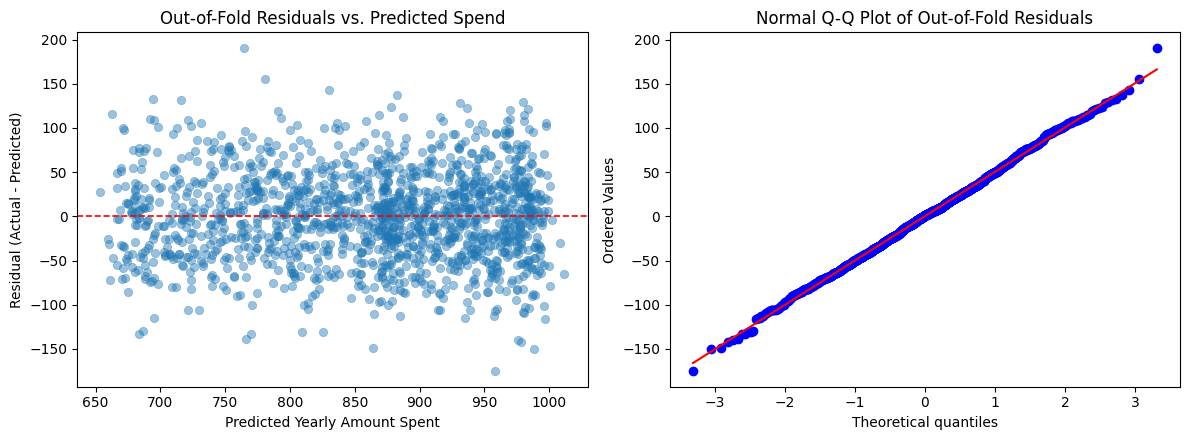

In [45]:
oof_preds = cross_val_predict(rfe_pipeline, X_interactions, y_spend, cv=cv)
residuals = y_spend - oof_preds

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(x=oof_preds, y=residuals, alpha=0.45, edgecolor=None, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0].set_title('Out-of-Fold Residuals vs. Predicted Spend')
axes[0].set_xlabel('Predicted Yearly Amount Spent')
axes[0].set_ylabel('Residual (Actual - Predicted)')

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot of Out-of-Fold Residuals')

plt.tight_layout()
plt.show()

In [46]:
scaler_diag = StandardScaler()
X_diag_scaled = pd.DataFrame(
    scaler_diag.fit_transform(X_interactions),
    columns=X_interactions.columns,
    index=X_interactions.index
)

rfe_diag = RFE(estimator=LinearRegression(), n_features_to_select=10).fit(X_diag_scaled, y_spend)
X_diag_sel = X_diag_scaled.loc[:, rfe_diag.support_]

squared_residuals = residuals ** 2
aux_reg = LinearRegression().fit(X_diag_sel, squared_residuals)
aux_r2 = aux_reg.score(X_diag_sel, squared_residuals)

n_samples, n_predictors = X_diag_sel.shape
lm_stat = n_samples * aux_r2
bp_p_value = stats.chi2.sf(lm_stat, df=n_predictors)

spearman_rho, spearman_p = stats.spearmanr(oof_preds, np.abs(residuals))

print(f"Breusch-Pagan Auxiliary R2: {aux_r2:.5f} | LM Stat: {lm_stat:.4f} | p-value: {bp_p_value:.4f}")
print(f"Spearman (Predicted vs |Residual|): rho = {spearman_rho:.4f} | p-value = {spearman_p:.4f}")

Breusch-Pagan Auxiliary R2: 0.00658 | LM Stat: 9.8740 | p-value: 0.4516
Spearman (Predicted vs |Residual|): rho = -0.0007 | p-value = 0.9783


In [47]:
from sklearn.linear_model import Ridge, Lasso

In [48]:
alphas = np.logspace(-2, 3, 25)

ridge_r2, ridge_rmse = [], []
lasso_r2, lasso_rmse, lasso_nonzero = [], [], []

scaler_grid = StandardScaler()
X_grid_scaled = scaler_grid.fit_transform(X_interactions)

for a in alphas:
    r_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=a, max_iter=10000))])
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    
    ridge_r2.append(cross_val_score(r_pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean())
    ridge_rmse.append(np.sqrt(-cross_val_score(r_pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean())
    
    lasso_r2.append(cross_val_score(l_pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean())
    lasso_rmse.append(np.sqrt(-cross_val_score(l_pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean())
    
    l_full = Lasso(alpha=a, max_iter=20000).fit(X_grid_scaled, y_spend)
    lasso_nonzero.append(int(np.sum(np.abs(l_full.coef_) > 1e-6)))

best_ridge_alpha = alphas[int(np.argmax(ridge_r2))]
best_lasso_alpha = alphas[int(np.argmax(lasso_r2))]

print(f"Best Ridge alpha: {best_ridge_alpha:.4f} (R2={max(ridge_r2):.4f})")
print(f"Best Lasso alpha: {best_lasso_alpha:.4f} (R2={max(lasso_r2):.4f})")

Best Ridge alpha: 0.2873 (R2=0.7726)
Best Lasso alpha: 0.2873 (R2=0.7751)


In [49]:
models_to_compare = {
    "OLS": Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    f"Ridge (alpha={best_ridge_alpha:.2f})": Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=best_ridge_alpha, max_iter=10000))]),
    f"Lasso (alpha={best_lasso_alpha:.2f})": Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=best_lasso_alpha, max_iter=20000))])
}

for label, pipe in models_to_compare.items():
    r2_m = cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean()
    rmse_m = np.sqrt(-cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean()
    mae_m = -cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_absolute_error').mean()
    print(f"{label:24s} | R2: {r2_m:.4f} | RMSE: {rmse_m:.4f} | MAE: {mae_m:.4f}")

OLS                      | R2: 0.7726 | RMSE: 50.1374 | MAE: 39.9342
Ridge (alpha=0.29)       | R2: 0.7726 | RMSE: 50.1365 | MAE: 39.9430
Lasso (alpha=0.29)       | R2: 0.7751 | RMSE: 49.8669 | MAE: 39.8060


In [50]:
scaler_coef = StandardScaler()
X_coef_scaled = pd.DataFrame(scaler_coef.fit_transform(X_interactions), columns=X_interactions.columns)

ols_c = LinearRegression().fit(X_coef_scaled, y_spend).coef_
ridge_opt_c = Ridge(alpha=best_ridge_alpha, max_iter=10000).fit(X_coef_scaled, y_spend).coef_
lasso_opt_c = Lasso(alpha=best_lasso_alpha, max_iter=20000).fit(X_coef_scaled, y_spend).coef_
lasso_strong_c = Lasso(alpha=10.0, max_iter=20000).fit(X_coef_scaled, y_spend).coef_

coef_table = pd.DataFrame({
    'feature': X_interactions.columns,
    'OLS': ols_c,
    'Ridge_opt': ridge_opt_c,
    'Lasso_opt': lasso_opt_c,
    'Lasso_a10': lasso_strong_c
})
coef_table['abs_ols'] = coef_table['OLS'].abs()
coef_table = coef_table.sort_values('abs_ols', ascending=False).drop(columns='abs_ols')

print(f"Non-zero features -> Lasso_opt: {np.sum(np.abs(lasso_opt_c) > 1e-6)}/{len(ols_c)}, Lasso_a10: {np.sum(np.abs(lasso_strong_c) > 1e-6)}/{len(ols_c)}")
print(coef_table.head(10).to_string(index=False))

Non-zero features -> Lasso_opt: 18/30, Lasso_a10: 1/30
                       feature        OLS  Ridge_opt  Lasso_opt  Lasso_a10
                           age 175.709576 173.350254 160.532791   81.89561
                         age^2 -90.395865 -88.675128 -71.505289    0.00000
                    age rating   7.117765   7.991908   1.465335    0.00000
rating positive_feedback_count  -6.608175  -6.615617  -1.876595   -0.00000
          department_name_Tops   3.926710   3.921672   3.341326    0.00000
       department_name_Jackets   3.891908   3.893844   3.451595    0.00000
           age recommended_ind  -2.955514  -3.137925  -0.000000    0.00000
        rating recommended_ind  -2.871212  -2.808815  -0.490172   -0.00000
     positive_feedback_count^2   2.505209   2.474380   1.667756    0.00000
   age positive_feedback_count   2.418660   2.465737   0.000000    0.00000


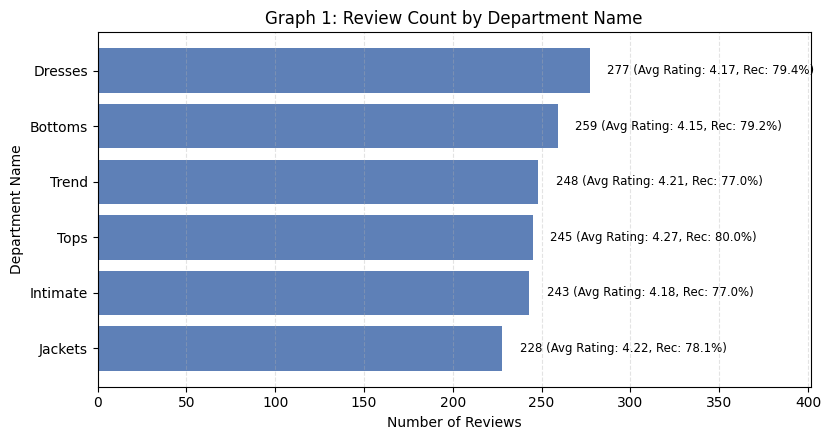

In [51]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

dept_summary = df.groupby('department_name').agg(
    review_count=('clothing_id', 'count'),
    avg_rating=('rating', 'mean'),
    rec_rate=('recommended_ind', lambda s: s.mean() * 100)
).sort_values('review_count', ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(dept_summary.index, dept_summary['review_count'], color='#4C72B0', alpha=0.9)
ax.set_title('Graph 1: Review Count by Department Name')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Department Name')
ax.grid(axis='x', linestyle='--', alpha=0.35)

for bar, (_, row) in zip(bars, dept_summary.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 10,
        bar.get_y() + bar.get_height() / 2,
        f"{int(w)} (Avg Rating: {row['avg_rating']:.2f}, Rec: {row['rec_rate']:.1f}%)",
        va='center',
        fontsize=8.5
    )

ax.set_xlim(0, dept_summary['review_count'].max() * 1.45)
plt.tight_layout()
plt.show()

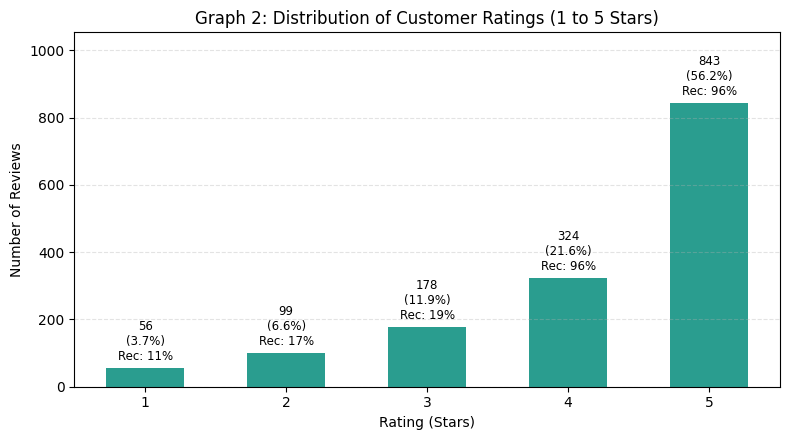

In [52]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

rating_summary = df.groupby('rating').agg(
    count=('clothing_id', 'count'),
    pct=('clothing_id', lambda s: len(s) / len(df) * 100),
    rec_pct=('recommended_ind', lambda s: s.mean() * 100)
).sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(rating_summary.index.astype(str), rating_summary['count'], color='#2A9D8F', width=0.55)
ax.set_title('Graph 2: Distribution of Customer Ratings (1 to 5 Stars)')
ax.set_xlabel('Rating (Stars)')
ax.set_ylabel('Number of Reviews')
ax.grid(axis='y', linestyle='--', alpha=0.35)

for bar, (_, row) in zip(bars, rating_summary.iterrows()):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 15,
        f"{int(h)}\n({row['pct']:.1f}%)\nRec: {row['rec_pct']:.0f}%",
        ha='center',
        va='bottom',
        fontsize=8.5
    )

ax.set_ylim(0, rating_summary['count'].max() * 1.25)
plt.tight_layout()
plt.show()

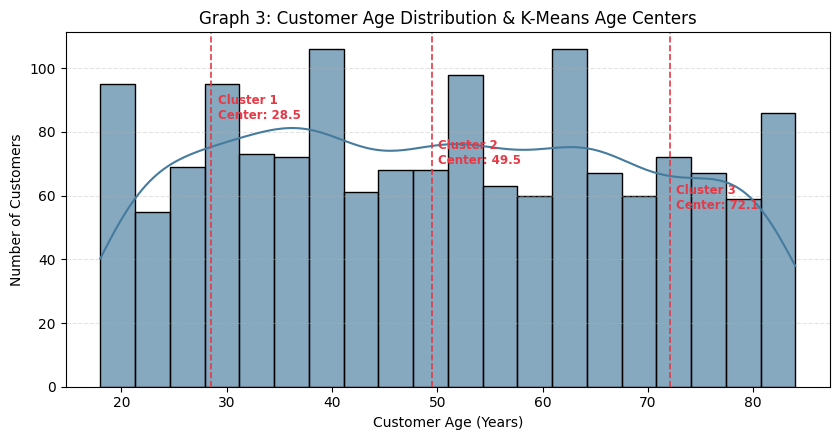

In [53]:
from sklearn.cluster import KMeans

df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(df[['age']])
df['age_cluster'] = clusters

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.histplot(df['age'], bins=20, kde=True, color='#457B9D', alpha=0.65, ax=ax)

centers = sorted(kmeans.cluster_centers_.flatten())
for idx, c in enumerate(centers, start=1):
    ax.axvline(c, color='#E63946', linestyle='--', linewidth=1.2)
    ax.text(
        c + 0.6,
        ax.get_ylim()[1] * 0.88 - idx * 14,
        f"Cluster {idx}\nCenter: {c:.1f}",
        color='#E63946',
        fontsize=8.5,
        fontweight='bold'
    )

ax.set_title('Graph 3: Customer Age Distribution & K-Means Age Centers')
ax.set_xlabel('Customer Age (Years)')
ax.set_ylabel('Number of Customers')
ax.grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

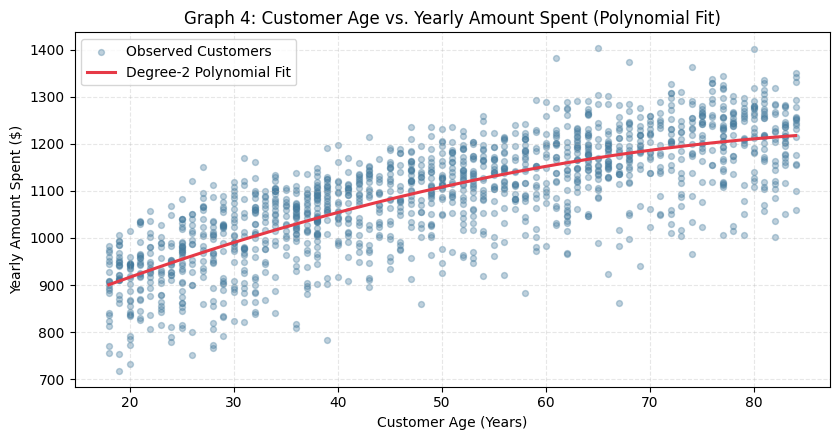

In [54]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[['age']])
model_poly = LinearRegression().fit(X_poly, df['yearly_amount_spent'])

age_grid = np.linspace(df['age'].min(), df['age'].max(), 200).reshape(-1, 1)
pred_grid = model_poly.predict(poly.transform(age_grid))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(df['age'], df['yearly_amount_spent'], alpha=0.35, s=18, color='#457B9D', label='Observed Customers')
ax.plot(age_grid, pred_grid, color='#E63946', linewidth=2.2, label='Degree-2 Polynomial Fit')
ax.set_title('Graph 4: Customer Age vs. Yearly Amount Spent (Polynomial Fit)')
ax.set_xlabel('Customer Age (Years)')
ax.set_ylabel('Yearly Amount Spent ($)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

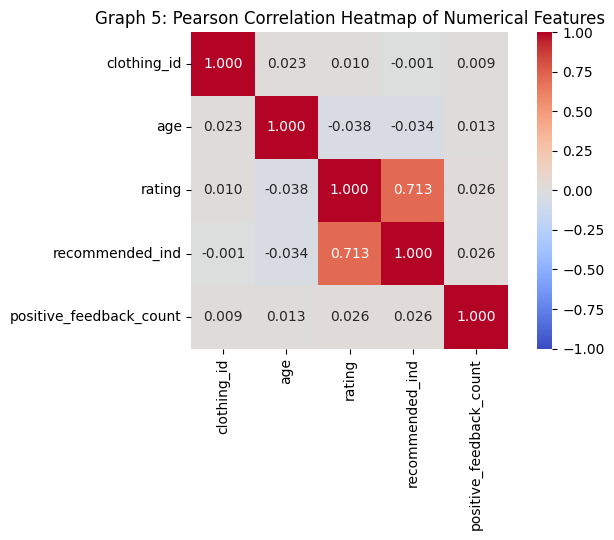

In [55]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

num_df = df[['clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count']]
corr = num_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(
    corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title('Graph 5: Pearson Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

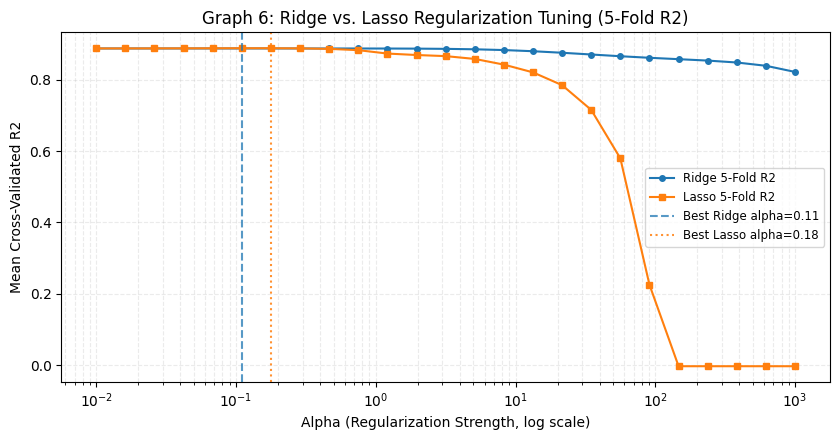

In [56]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

base_num = df[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(df[['division_name', 'department_name', 'class_name']], drop_first=True, dtype=float)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df.index
)
X = pd.concat([X_num_poly, cat_dummies], axis=1)
y = df['yearly_amount_spent']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = np.logspace(-2, 3, 25)
ridge_r2, lasso_r2 = [], []

for a in alphas:
    r_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=a, max_iter=10000))])
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    ridge_r2.append(cross_val_score(r_pipe, X, y, cv=cv, scoring='r2').mean())
    lasso_r2.append(cross_val_score(l_pipe, X, y, cv=cv, scoring='r2').mean())

best_r_alpha = alphas[int(np.argmax(ridge_r2))]
best_l_alpha = alphas[int(np.argmax(lasso_r2))]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.semilogx(alphas, ridge_r2, marker='o', markersize=4, label='Ridge 5-Fold R2')
ax.semilogx(alphas, lasso_r2, marker='s', markersize=4, label='Lasso 5-Fold R2')
ax.axvline(best_r_alpha, color='C0', linestyle='--', alpha=0.75, label=f'Best Ridge alpha={best_r_alpha:.2f}')
ax.axvline(best_l_alpha, color='C1', linestyle=':', alpha=0.85, label=f'Best Lasso alpha={best_l_alpha:.2f}')
ax.set_title('Graph 6: Ridge vs. Lasso Regularization Tuning (5-Fold R2)')
ax.set_xlabel('Alpha (Regularization Strength, log scale)')
ax.set_ylabel('Mean Cross-Validated R2')
ax.legend(fontsize=8.5)
ax.grid(True, which='both', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

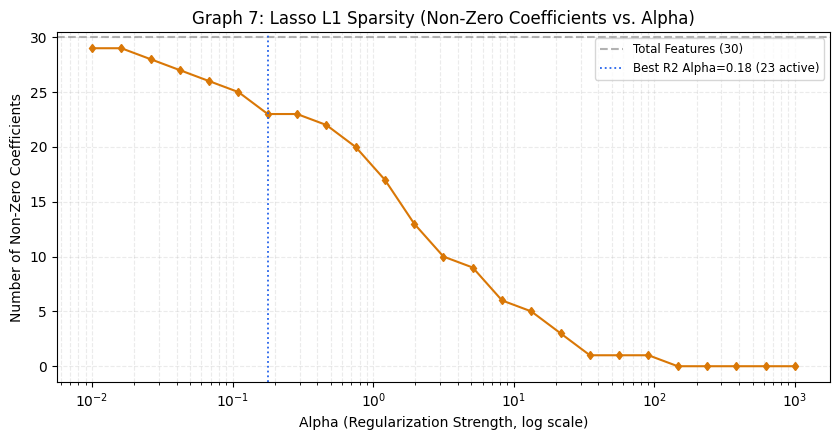

In [57]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

base_num = df[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(df[['division_name', 'department_name', 'class_name']], drop_first=True, dtype=float)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df.index
)
X = pd.concat([X_num_poly, cat_dummies], axis=1)
y = df['yearly_amount_spent']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = np.logspace(-2, 3, 25)
lasso_r2, lasso_nonzero = [], []

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for a in alphas:
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    lasso_r2.append(cross_val_score(l_pipe, X, y, cv=cv, scoring='r2').mean())
    l_full = Lasso(alpha=a, max_iter=20000).fit(X_scaled, y)
    lasso_nonzero.append(int(np.sum(np.abs(l_full.coef_) > 1e-6)))

best_l_alpha = alphas[int(np.argmax(lasso_r2))]
best_nz = lasso_nonzero[int(np.argmax(lasso_r2))]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.semilogx(alphas, lasso_nonzero, marker='d', markersize=4.5, color='#D97706')
ax.axhline(X.shape[1], color='gray', linestyle='--', alpha=0.6, label=f'Total Features ({X.shape[1]})')
ax.axvline(best_l_alpha, color='#2563EB', linestyle=':', linewidth=1.3, label=f'Best R2 Alpha={best_l_alpha:.2f} ({best_nz} active)')
ax.set_title('Graph 7: Lasso L1 Sparsity (Non-Zero Coefficients vs. Alpha)')
ax.set_xlabel('Alpha (Regularization Strength, log scale)')
ax.set_ylabel('Number of Non-Zero Coefficients')
ax.legend(fontsize=8.5)
ax.grid(True, which='both', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

In [58]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

In [59]:
df_tune = df_cleaned.copy() if 'df_cleaned' in locals() else df.copy()
df_tune.columns = [col.strip().lower().replace(' ', '_') for col in df_tune.columns]

num_cols = ['age', 'rating', 'positive_feedback_count']
cat_cols = ['division_name', 'department_name', 'class_name']

X_tune = df_tune[num_cols + cat_cols]
y_tune = df_tune['recommended_ind'].astype(int)

preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [60]:
baseline_rf = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(random_state=42))
])

base_acc = cross_val_score(baseline_rf, X_tune, y_tune, cv=skf, scoring='accuracy')
base_f1 = cross_val_score(baseline_rf, X_tune, y_tune, cv=skf, scoring='f1')

print(f"Baseline RF -> Accuracy: {base_acc.mean():.4f} (+/- {base_acc.std():.4f}) | F1: {base_f1.mean():.4f} (+/- {base_f1.std():.4f})")

Baseline RF -> Accuracy: 0.9133 (+/- 0.0156) | F1: 0.9453 (+/- 0.0099)


In [61]:
param_grid = {
    'clf__n_estimators': [100, 200],
    'clf__max_depth': [5, 10, None],
    'clf__min_samples_split': [2, 10],
    'clf__min_samples_leaf': [1, 4]
}

grid_search = GridSearchCV(
    estimator=Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=42))]),
    param_grid=param_grid,
    cv=skf,
    scoring='f1',
    n_jobs=-1
)
grid_search.fit(X_tune, y_tune)

grid_acc = cross_val_score(grid_search.best_estimator_, X_tune, y_tune, cv=skf, scoring='accuracy')
grid_f1 = cross_val_score(grid_search.best_estimator_, X_tune, y_tune, cv=skf, scoring='f1')

print("Best GridSearchCV Params:", grid_search.best_params_)
print(f"GridSearchCV RF -> Accuracy: {grid_acc.mean():.4f} (+/- {grid_acc.std():.4f}) | F1: {grid_f1.mean():.4f} (+/- {grid_f1.std():.4f})")

Best GridSearchCV Params: {'clf__max_depth': None, 'clf__min_samples_leaf': 4, 'clf__min_samples_split': 10, 'clf__n_estimators': 100}
GridSearchCV RF -> Accuracy: 0.9200 (+/- 0.0153) | F1: 0.9493 (+/- 0.0095)


In [62]:
param_distributions = {
    'clf__n_estimators': [50, 100, 150, 200],
    'clf__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'clf__max_depth': [2, 3, 4, 5],
    'clf__subsample': [0.7, 0.85, 1.0]
}

random_search = RandomizedSearchCV(
    estimator=Pipeline([('prep', preprocessor), ('clf', GradientBoostingClassifier(random_state=42))]),
    param_distributions=param_distributions,
    n_iter=15,
    cv=skf,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
random_search.fit(X_tune, y_tune)

rand_acc = cross_val_score(random_search.best_estimator_, X_tune, y_tune, cv=skf, scoring='accuracy')
rand_f1 = cross_val_score(random_search.best_estimator_, X_tune, y_tune, cv=skf, scoring='f1')

print("Best RandomizedSearchCV Params:", random_search.best_params_)
print(f"RandomizedSearchCV GB -> Accuracy: {rand_acc.mean():.4f} (+/- {rand_acc.std():.4f}) | F1: {rand_f1.mean():.4f} (+/- {rand_f1.std():.4f})")

Best RandomizedSearchCV Params: {'clf__subsample': 0.7, 'clf__n_estimators': 200, 'clf__max_depth': 2, 'clf__learning_rate': 0.01}
RandomizedSearchCV GB -> Accuracy: 0.9187 (+/- 0.0169) | F1: 0.9484 (+/- 0.0107)


In [63]:
# Cell T6: Short Bayesian Surrogate Optimization (no try/except)
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern

rng = np.random.default_rng(42)
params_grid = [
    {'n_estimators': int(rng.integers(50, 250)),
     'max_depth': int(rng.integers(3, 15)),
     'min_samples_leaf': int(rng.integers(1, 10))}
    for _ in range(20)
]

scores = [
    cross_val_score(
        Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(**p, random_state=42))]),
        X_tune, y_tune, cv=skf, scoring='f1'
    ).mean()
    for p in params_grid[:6]
]

X_obs = np.array([[p['n_estimators'], p['max_depth'], p['min_samples_leaf']] for p in params_grid[:6]], dtype=float)
X_cand = np.array([[p['n_estimators'], p['max_depth'], p['min_samples_leaf']] for p in params_grid[6:]], dtype=float)

gp = GaussianProcessRegressor(kernel=Matern(nu=2.5), normalize_y=True, random_state=42).fit(X_obs, scores)
mu, sigma = gp.predict(X_cand, return_std=True)
best_params = params_grid[6 + int(np.argmax(mu + 0.5 * sigma))]

bayes_estimator = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(**best_params, random_state=42))
])

bayes_acc = cross_val_score(bayes_estimator, X_tune, y_tune, cv=skf, scoring='accuracy')
bayes_f1 = cross_val_score(bayes_estimator, X_tune, y_tune, cv=skf, scoring='f1')

print("Best Bayesian Params:", best_params)
print(f"Bayesian Model -> Accuracy: {bayes_acc.mean():.4f} (+/- {bayes_acc.std():.4f}) | F1: {bayes_f1.mean():.4f} (+/- {bayes_f1.std():.4f})")

Best Bayesian Params: {'n_estimators': 140, 'max_depth': 5, 'min_samples_leaf': 1}
Bayesian Model -> Accuracy: 0.9133 (+/- 0.0153) | F1: 0.9454 (+/- 0.0096)


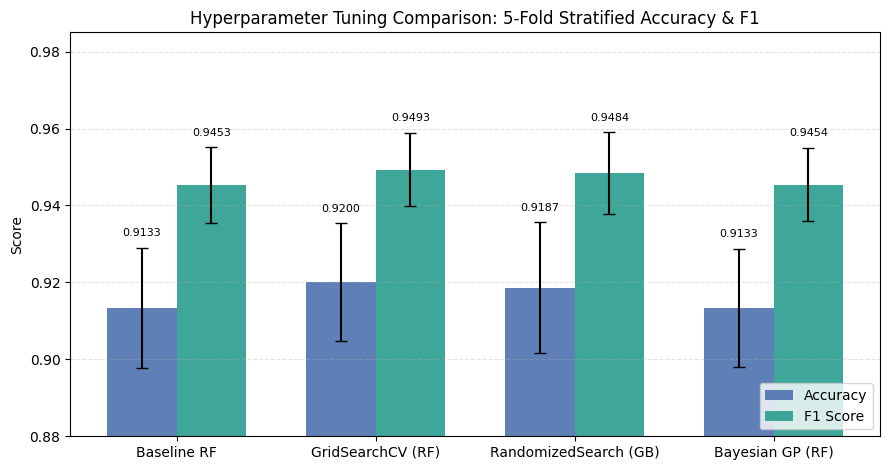

In [64]:
labels = ['Baseline RF', 'GridSearchCV (RF)', 'RandomizedSearch (GB)', 'Bayesian GP (RF)']
acc_means = np.array([base_acc.mean(), grid_acc.mean(), rand_acc.mean(), bayes_acc.mean()])
acc_stds  = np.array([base_acc.std(),  grid_acc.std(),  rand_acc.std(),  bayes_acc.std()])
f1_means  = np.array([base_f1.mean(),  grid_f1.mean(),  rand_f1.mean(),  bayes_f1.mean()])
f1_stds   = np.array([base_f1.std(),   grid_f1.std(),   rand_f1.std(),   bayes_f1.std()])

x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 4.8))
rects1 = ax.bar(x - width / 2, acc_means, width, yerr=acc_stds, capsize=4, label='Accuracy', color='#4C72B0', alpha=0.9)
rects2 = ax.bar(x + width / 2, f1_means,  width, yerr=f1_stds,  capsize=4, label='F1 Score', color='#2A9D8F', alpha=0.9)

ax.set_title('Hyperparameter Tuning Comparison: 5-Fold Stratified Accuracy & F1')
ax.set_ylabel('Score')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0.88, 0.985)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.35)

for r, sd in zip(rects1, acc_stds):
    h = r.get_height()
    ax.text(r.get_x() + r.get_width() / 2, h + sd + 0.0025, f"{h:.4f}", ha='center', va='bottom', fontsize=8)

for r, sd in zip(rects2, f1_stds):
    h = r.get_height()
    ax.text(r.get_x() + r.get_width() / 2, h + sd + 0.0025, f"{h:.4f}", ha='center', va='bottom', fontsize=8)

plt.tight_layout()
plt.show()

In [65]:


y_oof_pred = cross_val_predict(rfe_pipeline, X_interactions, y_spend, cv=cv)
oof_residuals = y_spend - y_oof_pred
abs_errors = np.abs(oof_residuals)

q25, q50, q75 = np.percentile(abs_errors, [25, 50, 75])
error_tier = np.where(
    abs_errors <= q25, 'Low Error (<= Q25)',
    np.where(abs_errors <= q75, 'Moderate Error (Q25-Q75)', 'High Error (> Q75)')
)

t_stat, p_val = stats.ttest_1samp(oof_residuals, 0.0)
rho_bias, p_rho = stats.spearmanr(y_oof_pred, oof_residuals)

print(f"Mean Bias: {oof_residuals.mean():.3f} (t={t_stat:.3f}, p={p_val:.4f}) | Median: {np.median(oof_residuals):.3f}")
print(f"Residual Skew: {stats.skew(oof_residuals):.3f} | Excess Kurtosis: {stats.kurtosis(oof_residuals):.3f}")
print(f"Spearman(Predicted, Residual): rho={rho_bias:.4f} (p={p_rho:.4f})")
print(f"|Error| Quartiles -> Q25: {q25:.2f}, Median: {q50:.2f}, Q75: {q75:.2f}")

Mean Bias: 0.116 (t=0.089, p=0.9288) | Median: 1.213
Residual Skew: 0.053 | Excess Kurtosis: 0.017
Spearman(Predicted, Residual): rho=-0.0001 (p=0.9960)
|Error| Quartiles -> Q25: 15.47, Median: 33.68, Q75: 57.77


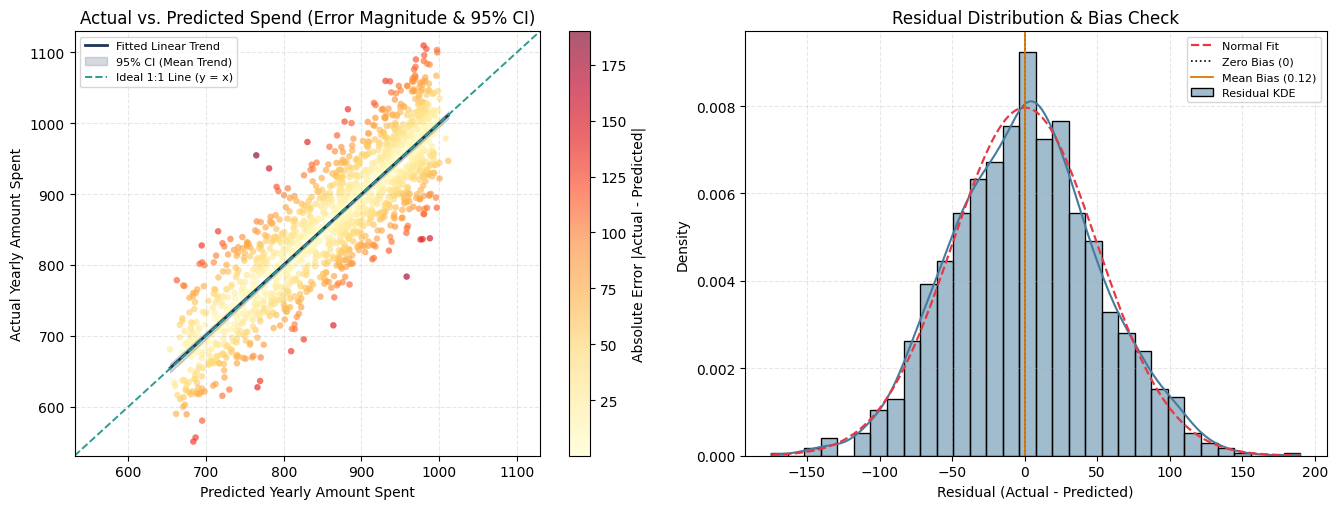

In [66]:
order = np.argsort(y_oof_pred)
x_sorted = y_oof_pred[order]
slope, intercept = np.polyfit(y_oof_pred, y_spend, 1)
line_fit = intercept + slope * x_sorted

n_obs = len(y_spend)
x_mean = np.mean(y_oof_pred)
s_err = np.sqrt(np.sum((y_spend - (intercept + slope * y_oof_pred)) ** 2) / (n_obs - 2))
t_crit = stats.t.ppf(0.975, df=n_obs - 2)
ci_95 = t_crit * s_err * np.sqrt(1.0 / n_obs + ((x_sorted - x_mean) ** 2) / np.sum((y_oof_pred - x_mean) ** 2))

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

sc = axes[0].scatter(y_oof_pred, y_spend, c=abs_errors, cmap='YlOrRd', alpha=0.65, s=22, edgecolor='none')
plt.colorbar(sc, ax=axes[0], label='Absolute Error |Actual - Predicted|')
axes[0].plot(x_sorted, line_fit, color='#1D3557', linewidth=2.0, label='Fitted Linear Trend')
axes[0].fill_between(x_sorted, line_fit - ci_95, line_fit + ci_95, color='#1D3557', alpha=0.18, label='95% CI (Mean Trend)')

lims = [min(y_spend.min(), y_oof_pred.min()) - 20, max(y_spend.max(), y_oof_pred.max()) + 20]
axes[0].plot(lims, lims, linestyle='--', color='#2A9D8F', linewidth=1.4, label='Ideal 1:1 Line (y = x)')
axes[0].set_xlim(lims)
axes[0].set_ylim(lims)
axes[0].set_title('Actual vs. Predicted Spend (Error Magnitude & 95% CI)')
axes[0].set_xlabel('Predicted Yearly Amount Spent')
axes[0].set_ylabel('Actual Yearly Amount Spent')
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True, linestyle='--', alpha=0.3)

sns.histplot(oof_residuals, bins=32, kde=True, stat='density', color='#457B9D', alpha=0.5, ax=axes[1], label='Residual KDE')
r_grid = np.linspace(oof_residuals.min(), oof_residuals.max(), 200)
axes[1].plot(
    r_grid,
    stats.norm.pdf(r_grid, loc=oof_residuals.mean(), scale=oof_residuals.std(ddof=1)),
    color='#E63946', linestyle='--', linewidth=1.6, label='Normal Fit'
)
axes[1].axvline(0, color='black', linestyle=':', linewidth=1.2, label='Zero Bias (0)')
axes[1].axvline(oof_residuals.mean(), color='#D97706', linestyle='-', linewidth=1.3, label=f'Mean Bias ({oof_residuals.mean():.2f})')
axes[1].set_title('Residual Distribution & Bias Check')
axes[1].set_xlabel('Residual (Actual - Predicted)')
axes[1].set_ylabel('Density')
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [67]:
import plotly.graph_objects as go

order = np.argsort(y_oof_pred)
x_sorted = np.asarray(y_oof_pred)[order]
y_sorted = np.asarray(y_spend)[order]

slope, intercept = np.polyfit(x_sorted, y_sorted, 1)
trend_y = intercept + slope * x_sorted

n_obs = len(x_sorted)
x_mean = np.mean(x_sorted)
s_err = np.sqrt(np.sum((y_sorted - trend_y) ** 2) / (n_obs - 2))
t_crit = stats.t.ppf(0.975, df=n_obs - 2)
ci_95 = t_crit * s_err * np.sqrt(1.0 / n_obs + ((x_sorted - x_mean) ** 2) / np.sum((x_sorted - x_mean) ** 2))

low = min(x_sorted.min(), y_sorted.min()) - 15
high = max(x_sorted.max(), y_sorted.max()) + 15

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=x_sorted, y=trend_y - ci_95,
    mode='lines', line=dict(width=0),
    showlegend=False, hoverinfo='skip'
))
fig.add_trace(go.Scatter(
    x=x_sorted, y=trend_y + ci_95,
    mode='lines', line=dict(width=0),
    fill='tonexty', fillcolor='rgba(29, 53, 87, 0.18)',
    name='95% CI', hoverinfo='skip'
))
fig.add_trace(go.Scatter(
    x=x_sorted, y=trend_y,
    mode='lines', line=dict(color='#1D3557', width=2.2),
    name='Fitted Trend'
))
fig.add_trace(go.Scatter(
    x=[low, high], y=[low, high],
    mode='lines', line=dict(color='#2A9D8F', width=1.6, dash='dash'),
    name='Ideal 1:1 (y = x)'
))
fig.add_trace(go.Scatter(
    x=y_oof_pred, y=y_spend,
    mode='markers', name='Customers',
    text=[f"Residual: {r:+.2f} | {t}" for r, t in zip(oof_residuals, error_tier)],
    marker=dict(
        size=7, opacity=0.8,
        color=abs_errors, colorscale='YlOrRd',
        colorbar=dict(title='|Error|', x=1.02, y=0.5, len=0.8)
    ),
    hovertemplate="Predicted: $%{x:.2f}<br>Actual: $%{y:.2f}<br>|Error|: $%{marker.color:.2f}<br>%{text}<extra></extra>"
))

fig.update_layout(
    title=dict(text='Actual vs. Predicted Yearly Spend', y=0.96),
    xaxis=dict(title='Predicted Spend', range=[low, high]),
    yaxis=dict(title='Actual Spend', range=[low, high]),
    legend=dict(orientation='h', yanchor='bottom', y=1.02, xanchor='left', x=0),
    margin=dict(t=95, r=110, b=60, l=65),
    width=850,
    height=520,
    template='plotly_white'
)
fig.show()

In [68]:
df_lr = df_cleaned.copy() if 'df_cleaned' in locals() else df.copy()
df_lr.columns = [col.strip().lower().replace(' ', '_') for col in df_lr.columns]

df_lr['high_rating'] = (df_lr['rating'] >= 4).astype(int)
df_lr['log_feedback'] = np.log1p(df_lr['positive_feedback_count'].clip(lower=0))
df_lr['rating_x_age'] = df_lr['rating'] * df_lr['age']

num_cols = ['age', 'rating', 'positive_feedback_count', 'high_rating', 'log_feedback', 'rating_x_age']
cat_cols = ['division_name', 'department_name', 'class_name']

X_lr = df_lr[num_cols + cat_cols]
y_lr = df_lr['recommended_ind'].astype(int)

preprocessor_lr = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])

skf_lr = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("Positive class share (recommended_ind=1):", round(y_lr.mean(), 4))

Positive class share (recommended_ind=1): 0.7847


In [69]:
from sklearn.utils.class_weight import compute_sample_weight

pipe_weighted = Pipeline([
    ('prep', preprocessor_lr),
    ('clf', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42))
])
res_weighted = cross_validate(
    pipe_weighted, X_lr, y_lr, cv=skf_lr,
    scoring=['accuracy', 'balanced_accuracy', 'f1', 'roc_auc']
)
print("Class-Weighted L2 -> Acc:", round(res_weighted['test_accuracy'].mean(), 4),
      "| BalAcc:", round(res_weighted['test_balanced_accuracy'].mean(), 4),
      "| F1:", round(res_weighted['test_f1'].mean(), 4),
      "| AUC:", round(res_weighted['test_roc_auc'].mean(), 4))

from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

for sampler_name, sampler in [
    ('SMOTE', SMOTE(random_state=42)),
    ('RandomUnderSampler', RandomUnderSampler(random_state=42))
]:
    imb_pipe = ImbPipeline([
        ('prep', preprocessor_lr),
        ('sampler', sampler),
        ('clf', LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42))
    ])
    res_imb = cross_validate(
        imb_pipe, X_lr, y_lr, cv=skf_lr,
        scoring=['accuracy', 'balanced_accuracy', 'f1', 'roc_auc']
    )
    print(f"{sampler_name:18s} -> Acc: {res_imb['test_accuracy'].mean():.4f}",
          f"| BalAcc: {res_imb['test_balanced_accuracy'].mean():.4f}",
          f"| F1: {res_imb['test_f1'].mean():.4f}",
          f"| AUC: {res_imb['test_roc_auc'].mean():.4f}")

NameError: name 'cross_validate' is not defined

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = [
    {
        'clf__penalty': ['l2'],
        'clf__solver': ['lbfgs'],
        'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
    },
    {
        'clf__penalty': ['l1'],
        'clf__solver': ['liblinear'],
        'clf__C': [0.01, 0.05, 0.1, 0.5, 1.0, 5.0]
    }
]

grid_lr = GridSearchCV(
    estimator=Pipeline([
        ('prep', preprocessor_lr),
        ('clf', LogisticRegression(class_weight='balanced', max_iter=2000, random_state=42))
    ]),
    param_grid=param_grid_lr,
    cv=skf_lr,
    scoring='f1',
    n_jobs=-1
)
grid_lr.fit(X_lr, y_lr)

print("Best Logistic Regression Params:", grid_lr.best_params_)
print("Best 5-Fold F1 Score:", round(grid_lr.best_score_, 4))

In [ ]:
best_prep = grid_lr.best_estimator_.named_steps['prep']
best_clf = grid_lr.best_estimator_.named_steps['clf']

ohe_names = list(best_prep.named_transformers_['cat'].get_feature_names_out(cat_cols))
all_feature_names = num_cols + ohe_names

coefs = best_clf.coef_[0]
interp_df = pd.DataFrame({
    'feature': all_feature_names,
    'log_odds_coef': coefs,
    'odds_ratio': np.exp(coefs),
    'zeroed_by_l1': np.isclose(coefs, 0.0, atol=1e-6)
}).sort_values(by='log_odds_coef', key=abs, ascending=False)

print(interp_df.to_string(index=False))

In [ ]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report
)

pipe_eval = Pipeline([
    ('prep', preprocessor_lr),
    ('clf', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42))
])

y_oof_cls = cross_val_predict(pipe_eval, X_lr, y_lr, cv=skf_lr, method='predict')
y_oof_prob = cross_val_predict(pipe_eval, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

print("Confusion Matrix:\n", confusion_matrix(y_lr, y_oof_cls))
print(f"Accuracy:  {accuracy_score(y_lr, y_oof_cls):.4f}")
print(f"Precision: {precision_score(y_lr, y_oof_cls):.4f}")
print(f"Recall:    {recall_score(y_lr, y_oof_cls):.4f}")
print(f"F1-Score:  {f1_score(y_lr, y_oof_cls):.4f}")
print(f"Kappa:     {cohen_kappa_score(y_lr, y_oof_cls):.4f}")
print(f"MCC:       {matthews_corrcoef(y_lr, y_oof_cls):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_lr, y_oof_prob):.4f}")
print(f"PR-AUC:    {average_precision_score(y_lr, y_oof_prob):.4f}")
print("\nClassification Report:\n", classification_report(y_lr, y_oof_cls, digits=4))

In [ ]:
thresholds = np.round(np.linspace(0.20, 0.80, 13), 2)
tradeoff_rows = []

for th in thresholds:
    preds_th = (y_oof_prob >= th).astype(int)
    tradeoff_rows.append({
        'threshold': th,
        'precision': precision_score(y_lr, preds_th, zero_division=0),
        'recall': recall_score(y_lr, preds_th, zero_division=0),
        'f1': f1_score(y_lr, preds_th, zero_division=0),
        'mcc': matthews_corrcoef(y_lr, preds_th)
    })

tradeoff_df = pd.DataFrame(tradeoff_rows)
best_f1_th = tradeoff_df.loc[tradeoff_df['f1'].idxmax(), 'threshold']
best_mcc_th = tradeoff_df.loc[tradeoff_df['mcc'].idxmax(), 'threshold']

print(tradeoff_df.round(4).to_string(index=False))
print(f"\nBest F1 Threshold: {best_f1_th} | Best MCC Threshold: {best_mcc_th}")

In [ ]:
from sklearn.metrics import roc_curve, precision_recall_curve

fpr, tpr, _ = roc_curve(y_lr, y_oof_prob)
prec_vals, rec_vals, _ = precision_recall_curve(y_lr, y_oof_prob)
roc_val = roc_auc_score(y_lr, y_oof_prob)
pr_val = average_precision_score(y_lr, y_oof_prob)
pos_rate = y_lr.mean()

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8))

axes[0].plot(fpr, tpr, color='#1D3557', linewidth=2.2, label=f'Logistic Regression (AUC = {roc_val:.4f})')
axes[0].plot([0, 1], [0, 1], linestyle='--', color='gray', linewidth=1.2, label='Random (0.5000)')
axes[0].set_title('Out-of-Fold ROC-AUC Curve')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle='--', alpha=0.3)

axes[1].plot(rec_vals, prec_vals, color='#2A9D8F', linewidth=2.2, label=f'Logistic Regression (PR-AUC = {pr_val:.4f})')
axes[1].axhline(pos_rate, linestyle='--', color='gray', linewidth=1.2, label=f'No-Skill Baseline ({pos_rate:.4f})')
axes[1].set_title('Out-of-Fold Precision-Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='lower left')
axes[1].grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
lr_prob_oof = cross_val_predict(pipe_eval, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]
rf_prob_oof = cross_val_predict(grid_search.best_estimator_, X_tune, y_tune, cv=skf_lr, method='predict_proba')[:, 1]
gb_prob_oof = cross_val_predict(random_search.best_estimator_, X_tune, y_tune, cv=skf_lr, method='predict_proba')[:, 1]

fig, ax = plt.subplots(figsize=(8.2, 5.2))

for label, probs, color, style in [
    ('Logistic Regression (Balanced L2)', lr_prob_oof, '#1D3557', '-'),
    ('Tuned Random Forest', rf_prob_oof, '#2A9D8F', '--'),
    ('Tuned Gradient Boosting', gb_prob_oof, '#E63946', '-.'),
]:
    fpr_m, tpr_m, _ = roc_curve(y_lr, probs)
    auc_m = roc_auc_score(y_lr, probs)
    ax.plot(fpr_m, tpr_m, color=color, linestyle=style, linewidth=2.1, label=f'{label} (AUC = {auc_m:.4f})')

ax.plot([0, 1], [0, 1], linestyle=':', color='gray', linewidth=1.2, label='Random Classifier (AUC = 0.5000)')
ax.set_title('Out-of-Fold ROC-AUC Comparison Across Classifiers')
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall)')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score
)

rf_param_dist = {
    'clf__n_estimators': [100, 150, 200, 300],
    'clf__max_depth': [4, 6, 8, 12, None],
    'clf__min_samples_split': [2, 5, 10],
    'clf__min_samples_leaf': [1, 2, 4, 6],
    'clf__max_features': ['sqrt', 'log2', None]
}

rf_random_search = RandomizedSearchCV(
    estimator=Pipeline([
        ('prep', preprocessor_lr),
        ('clf', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
    ]),
    param_distributions=rf_param_dist,
    n_iter=20,
    cv=skf_lr,
    scoring='f1',
    random_state=42,
    n_jobs=-1
)
rf_random_search.fit(X_lr, y_lr)
best_rf_pipe = rf_random_search.best_estimator_

lr_pred = cross_val_predict(pipe_eval, X_lr, y_lr, cv=skf_lr, method='predict')
lr_prob = cross_val_predict(pipe_eval, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

rf_pred = cross_val_predict(best_rf_pipe, X_lr, y_lr, cv=skf_lr, method='predict')
rf_prob = cross_val_predict(best_rf_pipe, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

def cls_metrics(y_true, y_p, y_pr):
    return {
        'Accuracy': accuracy_score(y_true, y_p),
        'Precision': precision_score(y_true, y_p),
        'Recall': recall_score(y_true, y_p),
        'F1': f1_score(y_true, y_p),
        'Kappa': cohen_kappa_score(y_true, y_p),
        'MCC': matthews_corrcoef(y_true, y_p),
        'ROC_AUC': roc_auc_score(y_true, y_pr)
    }

model_comp = pd.DataFrame([
    {'Model': 'Logistic Regression (L2, Balanced)', **cls_metrics(y_lr, lr_pred, lr_prob)},
    {'Model': 'Random Forest (RandomizedSearchCV)', **cls_metrics(y_lr, rf_pred, rf_prob)}
])

print("Best RF Params:", rf_random_search.best_params_)
print("\nComparison Table:\n", model_comp.round(4).to_string(index=False))

In [ ]:
from sklearn.inspection import permutation_importance

best_rf_pipe.fit(X_lr, y_lr)
prep_fitted = best_rf_pipe.named_steps['prep']
rf_fitted = best_rf_pipe.named_steps['clf']

X_lr_proc = prep_fitted.transform(X_lr)
ohe_cols = list(prep_fitted.named_transformers_['cat'].get_feature_names_out(cat_cols))
rf_feature_names = num_cols + ohe_cols

perm_res = permutation_importance(
    rf_fitted, X_lr_proc, y_lr,
    n_repeats=15, random_state=42, scoring='f1', n_jobs=-1
)

imp_table = pd.DataFrame({
    'feature': rf_feature_names,
    'MDI_Importance': rf_fitted.feature_importances_,
    'Perm_F1_Mean': perm_res.importances_mean,
    'Perm_F1_Std': perm_res.importances_std
}).sort_values('MDI_Importance', ascending=False)

print(imp_table.round(4).to_string(index=False))

In [ ]:
explainer = shap.TreeExplainer(rf_fitted)
shap_values = explainer.shap_values(X_lr_proc)

# Extract class 1 SHAP matrix cleanly across SHAP versions
if isinstance(shap_values, list):
    sv_pos = shap_values[1]
elif getattr(shap_values, 'ndim', 0) == 3:
    sv_pos = shap_values[:, :, 1]
else:
    sv_pos = shap_values

mean_abs_shap = np.mean(np.abs(sv_pos), axis=0)
shap_summary = pd.DataFrame({
    'feature': rf_feature_names,
    'mean_abs_shap': mean_abs_shap
}).sort_values('mean_abs_shap', ascending=False)

print("Top Features by Mean |SHAP|:\n", shap_summary.round(4).to_string(index=False))

shap.summary_plot(sv_pos, X_lr_proc, feature_names=rf_feature_names, show=False)
plt.title('SHAP Summary Plot for P(Recommended = 1)')
plt.tight_layout()
plt.show()

In [ ]:
sample_idx = 0
row_df = X_lr.iloc[[sample_idx]]
pred_cls = int(best_rf_pipe.predict(row_df)[0])
pred_prob = float(best_rf_pipe.predict_proba(row_df)[0, 1])
actual_cls = int(y_lr.iloc[sample_idx])

print(f"Row {sample_idx} -> Actual: {actual_cls} | Predicted: {pred_cls} | P(Recommended=1): {pred_prob:.4f}")

In [ ]:
from sklearn.svm import SVC

svm_kernels = {
    'Linear (C=1.0)': SVC(kernel='linear', C=1.0, class_weight='balanced', probability=True, random_state=42),
    'Polynomial (deg=3, C=1.0)': SVC(kernel='poly', degree=3, C=1.0, class_weight='balanced', probability=True, random_state=42),
    'RBF (C=1.0, gamma=scale)': SVC(kernel='rbf', C=1.0, gamma='scale', class_weight='balanced', probability=True, random_state=42),
}

kernel_results = []
for name, clf_svm in svm_kernels.items():
    pipe_svm = Pipeline([('prep', preprocessor_lr), ('clf', clf_svm)])
    p_cls = cross_val_predict(pipe_svm, X_lr, y_lr, cv=skf_lr, method='predict')
    p_prob = cross_val_predict(pipe_svm, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]
    kernel_results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_lr, p_cls),
        'Precision': precision_score(y_lr, p_cls),
        'Recall': recall_score(y_lr, p_cls),
        'F1': f1_score(y_lr, p_cls),
        'Kappa': cohen_kappa_score(y_lr, p_cls),
        'MCC': matthews_corrcoef(y_lr, p_cls),
        'ROC_AUC': roc_auc_score(y_lr, p_prob)
    })

print(pd.DataFrame(kernel_results).round(4).to_string(index=False))

In [ ]:
from sklearn.model_selection import GridSearchCV

svm_param_grid = [
    {'clf__kernel': ['linear'], 'clf__C': [0.1, 1.0, 10.0]},
    {'clf__kernel': ['poly'], 'clf__degree': [2, 3], 'clf__C': [0.5, 1.0, 5.0], 'clf__gamma': ['scale', 'auto']},
    {'clf__kernel': ['rbf'], 'clf__C': [0.1, 1.0, 10.0], 'clf__gamma': ['scale', 'auto', 0.05]}
]

grid_svm = GridSearchCV(
    estimator=Pipeline([
        ('prep', preprocessor_lr),
        ('clf', SVC(class_weight='balanced', probability=True, random_state=42))
    ]),
    param_grid=svm_param_grid,
    cv=skf_lr,
    scoring='f1',
    n_jobs=-1
)
grid_svm.fit(X_lr, y_lr)
best_svm_pipe = grid_svm.best_estimator_

best_cls = cross_val_predict(best_svm_pipe, X_lr, y_lr, cv=skf_lr, method='predict')
best_prob = cross_val_predict(best_svm_pipe, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

print("Best SVM Params:", grid_svm.best_params_)
print(f"Best SVM 5-Fold F1: {f1_score(y_lr, best_cls):.4f} | ROC-AUC: {roc_auc_score(y_lr, best_prob):.4f} | MCC: {matthews_corrcoef(y_lr, best_cls):.4f}")

In [ ]:
X_2d = X_lr[['rating', 'age']].copy()
r_grid, a_grid = np.meshgrid(
    np.linspace(X_2d['rating'].min() - 0.5, X_2d['rating'].max() + 0.5, 200),
    np.linspace(X_2d['age'].min() - 3, X_2d['age'].max() + 3, 200)
)
grid_df = pd.DataFrame({'rating': r_grid.ravel(), 'age': a_grid.ravel()})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
rng_j = np.random.default_rng(42)

for ax, kern, title in [
    (axes[0], 'linear', 'Linear SVM Boundary (Rating vs. Age)'),
    (axes[1], 'rbf', 'RBF SVM Boundary (Rating vs. Age)')
]:
    pipe_2d = Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel=kern, C=1.0, gamma='scale', class_weight='balanced', random_state=42))
    ]).fit(X_2d, y_lr)

    z_vals = pipe_2d.decision_function(grid_df).reshape(r_grid.shape)
    ax.contourf(r_grid, a_grid, z_vals, levels=25, cmap='RdBu', alpha=0.55)
    ax.contour(r_grid, a_grid, z_vals, levels=[-1, 0, 1], colors=['#457B9D', '#111111', '#E63946'],
               linestyles=['--', '-', '--'], linewidths=[1.2, 2.0, 1.2])

    r_jitter = X_2d['rating'] + rng_j.uniform(-0.14, 0.14, size=len(X_2d))
    ax.scatter(r_jitter[y_lr == 0], X_2d['age'][y_lr == 0], c='#1D3557', s=14, alpha=0.55, label='Not Rec (0)')
    ax.scatter(r_jitter[y_lr == 1], X_2d['age'][y_lr == 1], c='#E63946', s=14, alpha=0.45, marker='^', label='Recommended (1)')
    ax.set_title(title)
    ax.set_xlabel('Rating (1–5, slightly jittered)')
    ax.set_ylabel('Customer Age (Years)')
    ax.set_xticks([1, 2, 3, 4, 5])
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.3)

plt.tight_layout()
plt.show()

In [73]:
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import Matern
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score, average_precision_score
)

pos_weight = float((y_lr == 0).sum() / max((y_lr == 1).sum(), 1))
rng_xgb = np.random.default_rng(42)

xgb_candidates = [
    {
        'n_estimators': int(rng_xgb.integers(60, 260)),
        'max_depth': int(rng_xgb.integers(2, 8)),
        'learning_rate': float(np.round(rng_xgb.uniform(0.01, 0.20), 3)),
        'subsample': float(np.round(rng_xgb.uniform(0.65, 1.0), 2)),
        'colsample_bytree': float(np.round(rng_xgb.uniform(0.60, 1.0), 2))
    }
    for _ in range(28)
]

def build_xgb_pipe(p):
    return Pipeline([
        ('prep', preprocessor_lr),
        ('clf', XGBClassifier(
            n_estimators=p['n_estimators'],
            max_depth=p['max_depth'],
            learning_rate=p['learning_rate'],
            subsample=p['subsample'],
            colsample_bytree=p['colsample_bytree'],
            scale_pos_weight=pos_weight,
            eval_metric='logloss',
            random_state=42,
            n_jobs=-1
        ))
    ])

def vec_xgb(p):
    return [p['n_estimators'], p['max_depth'], p['learning_rate'], p['subsample'], p['colsample_bytree']]

init_n = 8
init_f1 = [
    f1_score(y_lr, cross_val_predict(build_xgb_pipe(p), X_lr, y_lr, cv=skf_lr, method='predict'))
    for p in xgb_candidates[:init_n]
]

gp_xgb = GaussianProcessRegressor(kernel=Matern(nu=2.5), normalize_y=True, random_state=42).fit(
    np.array([vec_xgb(p) for p in xgb_candidates[:init_n]], dtype=float),
    np.array(init_f1)
)
X_cand_xgb = np.array([vec_xgb(p) for p in xgb_candidates[init_n:]], dtype=float)
mu_xgb, std_xgb = gp_xgb.predict(X_cand_xgb, return_std=True)
best_xgb_params = xgb_candidates[init_n + int(np.argmax(mu_xgb + 0.6 * std_xgb))]

best_xgb_pipe = build_xgb_pipe(best_xgb_params)
xgb_pred = cross_val_predict(best_xgb_pipe, X_lr, y_lr, cv=skf_lr, method='predict')
xgb_prob = cross_val_predict(best_xgb_pipe, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

print("Best Bayesian XGBoost Params:", best_xgb_params)
print(f"Accuracy:  {accuracy_score(y_lr, xgb_pred):.4f}")
print(f"Precision: {precision_score(y_lr, xgb_pred):.4f}")
print(f"Recall:    {recall_score(y_lr, xgb_pred):.4f}")
print(f"F1-Score:  {f1_score(y_lr, xgb_pred):.4f}")
print(f"Kappa:     {cohen_kappa_score(y_lr, xgb_pred):.4f}")
print(f"MCC:       {matthews_corrcoef(y_lr, xgb_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_lr, xgb_prob):.4f}")
print(f"PR-AUC:    {average_precision_score(y_lr, xgb_prob):.4f}")

Best Bayesian XGBoost Params: {'n_estimators': 171, 'max_depth': 4, 'learning_rate': 0.118, 'subsample': 0.7, 'colsample_bytree': 0.65}
Accuracy:  0.9040
Precision: 0.9480
Recall:    0.9286
F1-Score:  0.9382
Kappa:     0.7234
MCC:       0.7241
ROC-AUC:   0.8845
PR-AUC:    0.9413


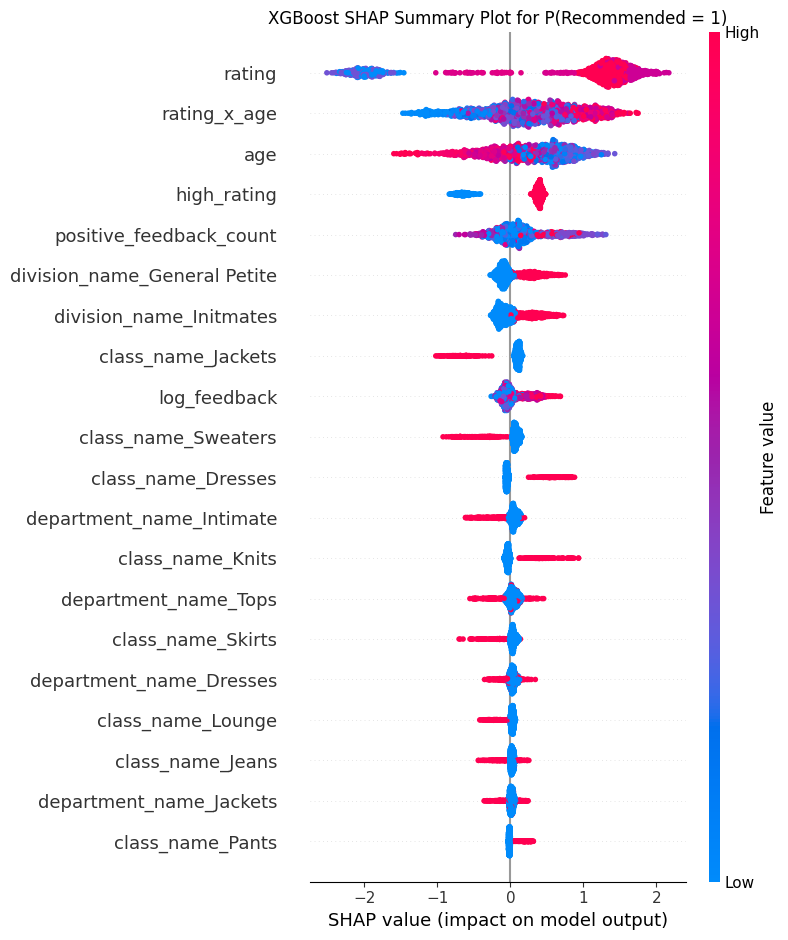

In [77]:
import shap

prep_xgb = best_xgb_pipe.named_steps['prep']
xgb_clf = best_xgb_pipe.named_steps['clf']

X_xgb_proc = prep_xgb.transform(X_lr)
xgb_feat_names = num_cols + list(prep_xgb.named_transformers_['cat'].get_feature_names_out(cat_cols))

explainer_xgb = shap.TreeExplainer(xgb_clf)
shap_vals_xgb = explainer_xgb.shap_values(X_xgb_proc)
sv_xgb_pos = shap_vals_xgb[1] if isinstance(shap_vals_xgb, list) else (
    shap_vals_xgb[:, :, 1] if getattr(shap_vals_xgb, 'ndim', 0) == 3 else shap_vals_xgb
)

shap.summary_plot(sv_xgb_pos, X_xgb_proc, feature_names=xgb_feat_names, show=False)
plt.title('XGBoost SHAP Summary Plot for P(Recommended = 1)')
plt.tight_layout()
plt.show()

In [78]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    cohen_kappa_score, matthews_corrcoef, roc_auc_score, average_precision_score
)

gb_configs = [
    {'learning_rate': 0.05, 'max_depth': 2, 'subsample': 0.80, 'n_estimators': 250},
    {'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.80, 'n_estimators': 250},
    {'learning_rate': 0.03, 'max_depth': 2, 'subsample': 0.75, 'n_estimators': 300},
    {'learning_rate': 0.10, 'max_depth': 3, 'subsample': 1.00, 'n_estimators': 250},
]

gb_rows = []
gb_pipes = {}

for cfg in gb_configs:
    tag = f"lr={cfg['learning_rate']}_d={cfg['max_depth']}_sub={cfg['subsample']}"
    pipe_gb = Pipeline([
        ('prep', preprocessor_lr),
        ('clf', GradientBoostingClassifier(
            learning_rate=cfg['learning_rate'],
            max_depth=cfg['max_depth'],
            subsample=cfg['subsample'],
            n_estimators=cfg['n_estimators'],
            n_iter_no_change=12,
            validation_fraction=0.15,
            tol=1e-4,
            random_state=42
        ))
    ])
    oof_cls = cross_val_predict(pipe_gb, X_lr, y_lr, cv=skf_lr, method='predict')
    oof_prb = cross_val_predict(pipe_gb, X_lr, y_lr, cv=skf_lr, method='predict_proba')[:, 1]

    pipe_gb.fit(X_lr, y_lr)
    gb_pipes[tag] = pipe_gb

    gb_rows.append({
        'config': tag,
        'used_trees': int(pipe_gb.named_steps['clf'].n_estimators_),
        'Accuracy': accuracy_score(y_lr, oof_cls),
        'Precision': precision_score(y_lr, oof_cls),
        'Recall': recall_score(y_lr, oof_cls),
        'F1': f1_score(y_lr, oof_cls),
        'Kappa': cohen_kappa_score(y_lr, oof_cls),
        'MCC': matthews_corrcoef(y_lr, oof_cls),
        'ROC_AUC': roc_auc_score(y_lr, oof_prb),
        'PR_AUC': average_precision_score(y_lr, oof_prb)
    })

gb_summary = pd.DataFrame(gb_rows).sort_values('F1', ascending=False)
best_gb_tag = gb_summary.iloc[0]['config']
best_gb_pipe = gb_pipes[best_gb_tag]

print("Best GB Config:", best_gb_tag)
print(gb_summary.round(4).to_string(index=False))

Best GB Config: lr=0.05_d=2_sub=0.8
              config  used_trees  Accuracy  Precision  Recall     F1  Kappa    MCC  ROC_AUC  PR_AUC
 lr=0.05_d=2_sub=0.8         113    0.9187     0.9451  0.9516 0.9483 0.7571 0.7572   0.8886  0.9472
lr=0.03_d=2_sub=0.75         191    0.9187     0.9451  0.9516 0.9483 0.7571 0.7572   0.8894  0.9482
 lr=0.05_d=3_sub=0.8          80    0.9173     0.9436  0.9516 0.9475 0.7526 0.7527   0.8879  0.9441
  lr=0.1_d=3_sub=1.0          61    0.9173     0.9436  0.9516 0.9475 0.7526 0.7527   0.8893  0.9467


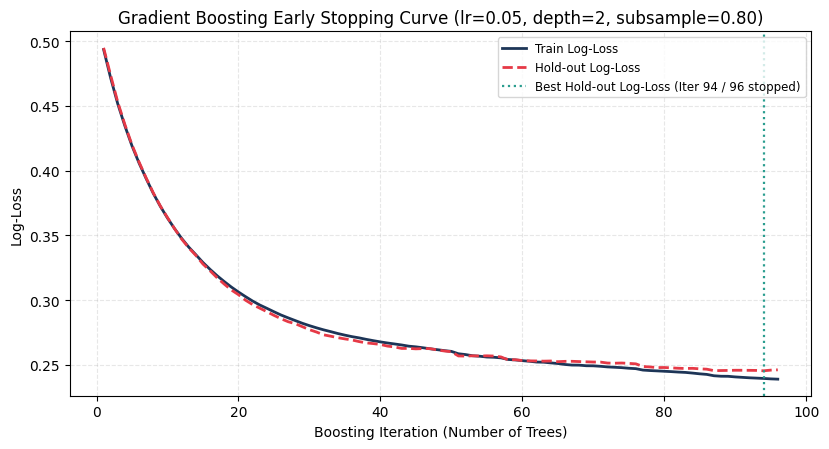

In [79]:
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import log_loss

X_tr_gb, X_te_gb, y_tr_gb, y_te_gb = train_test_split(
    X_lr, y_lr, test_size=0.25, stratify=y_lr, random_state=42
)

prep_gb_split = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
])
X_tr_gb_p = prep_gb_split.fit_transform(X_tr_gb)
X_te_gb_p = prep_gb_split.transform(X_te_gb)

gb_staged = GradientBoostingClassifier(
    learning_rate=0.05,
    max_depth=2,
    subsample=0.80,
    n_estimators=250,
    n_iter_no_change=12,
    validation_fraction=0.15,
    tol=1e-4,
    random_state=42
).fit(X_tr_gb_p, y_tr_gb)

train_losses = [log_loss(y_tr_gb, p) for p in gb_staged.staged_predict_proba(X_tr_gb_p)]
test_losses = [log_loss(y_te_gb, p) for p in gb_staged.staged_predict_proba(X_te_gb_p)]
opt_iter = int(np.argmin(test_losses)) + 1

fig, ax = plt.subplots(figsize=(8.4, 4.6))
stages = np.arange(1, len(train_losses) + 1)
ax.plot(stages, train_losses, label='Train Log-Loss', color='#1D3557', linewidth=2.0)
ax.plot(stages, test_losses, label='Hold-out Log-Loss', color='#E63946', linewidth=2.0, linestyle='--')
ax.axvline(opt_iter, color='#2A9D8F', linestyle=':', linewidth=1.6,
           label=f'Best Hold-out Log-Loss (Iter {opt_iter} / {len(stages)} stopped)')
ax.set_title('Gradient Boosting Early Stopping Curve (lr=0.05, depth=2, subsample=0.80)')
ax.set_xlabel('Boosting Iteration (Number of Trees)')
ax.set_ylabel('Log-Loss')
ax.legend(loc='upper right', fontsize=8.5)
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [83]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

best_rf_pipe = Pipeline([
    ('prep', preprocessor_lr),
    ('clf', RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features='sqrt',
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

In [84]:
from sklearn.model_selection import StratifiedKFold, cross_validate

skf_models = {
    'Logistic Regression': pipe_eval,
    'Random Forest': best_rf_pipe
}

stability_rows = []
fold_f1_5 = {}

for k in [5, 10]:
    skf_k = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    for m_name, m_pipe in skf_models.items():
        scores = cross_validate(m_pipe, X_lr, y_lr, cv=skf_k, scoring=['accuracy', 'f1', 'roc_auc'])
        stability_rows.append({
            'cv': f'Stratified {k}-Fold',
            'model': m_name,
            'acc_mean': scores['test_accuracy'].mean(),
            'acc_std': scores['test_accuracy'].std(),
            'f1_mean': scores['test_f1'].mean(),
            'f1_std': scores['test_f1'].std(),
            'f1_min': scores['test_f1'].min(),
            'f1_max': scores['test_f1'].max(),
            'auc_mean': scores['test_roc_auc'].mean(),
            'auc_std': scores['test_roc_auc'].std()
        })
        if k == 5:
            fold_f1_5[m_name] = scores['test_f1']

print(pd.DataFrame(stability_rows).round(4).to_string(index=False))
for m_name, arr in fold_f1_5.items():
    print(f"{m_name} 5-Fold F1 per fold:", np.round(arr, 4))

                cv               model  acc_mean  acc_std  f1_mean  f1_std  f1_min  f1_max  auc_mean  auc_std
 Stratified 5-Fold Logistic Regression    0.9187   0.0141   0.9484  0.0087  0.9367  0.9574    0.8839   0.0198
 Stratified 5-Fold       Random Forest    0.9180   0.0151   0.9479  0.0095  0.9367  0.9598    0.8867   0.0190
Stratified 10-Fold Logistic Regression    0.9193   0.0239   0.9488  0.0152  0.9191  0.9702    0.8854   0.0319
Stratified 10-Fold       Random Forest    0.9187   0.0251   0.9483  0.0160  0.9191  0.9702    0.8955   0.0292
Logistic Regression 5-Fold F1 per fold: [0.9554 0.9534 0.9389 0.9367 0.9574]
Random Forest 5-Fold F1 per fold: [0.9598 0.9534 0.9367 0.9367 0.953 ]


In [85]:
from sklearn.model_selection import LeaveOneOut, cross_val_score

rng_loo = np.random.default_rng(42)
pos_idx = y_lr[y_lr == 1].index.to_numpy()
neg_idx = y_lr[y_lr == 0].index.to_numpy()
n_small = min(120, len(y_lr))
n_pos = int(round(n_small * y_lr.mean()))
n_neg = n_small - n_pos

small_idx = np.concatenate([
    rng_loo.choice(pos_idx, size=min(n_pos, len(pos_idx)), replace=False),
    rng_loo.choice(neg_idx, size=min(n_neg, len(neg_idx)), replace=False)
])
rng_loo.shuffle(small_idx)

X_small = X_lr.loc[small_idx].reset_index(drop=True)
y_small = y_lr.loc[small_idx].reset_index(drop=True)

loo = LeaveOneOut()
loo_lr_scores = cross_val_score(pipe_eval, X_small, y_small, cv=loo, scoring='accuracy', n_jobs=-1)
loo_rf_scores = cross_val_score(best_rf_pipe, X_small, y_small, cv=loo, scoring='accuracy', n_jobs=-1)

print(f"LOOCV (n={len(X_small)}) Logistic Regression Accuracy: {loo_lr_scores.mean():.4f}")
print(f"LOOCV (n={len(X_small)}) Random Forest Accuracy:       {loo_rf_scores.mean():.4f}")

LOOCV (n=120) Logistic Regression Accuracy: 0.8667
LOOCV (n=120) Random Forest Accuracy:       0.8750


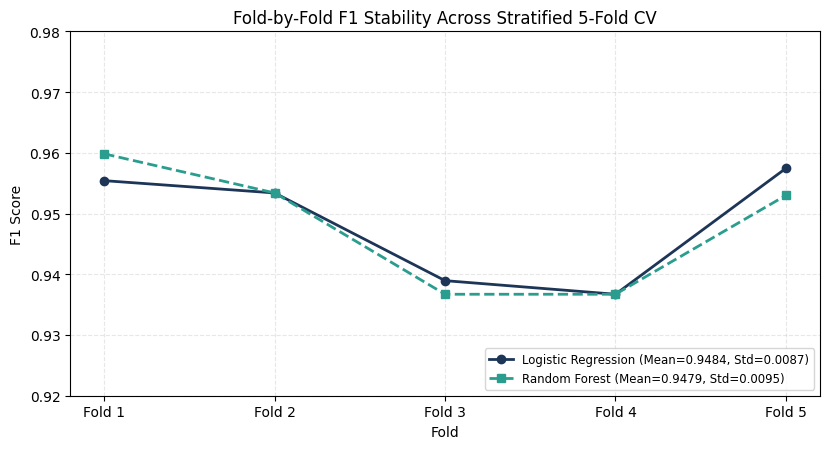

In [86]:
folds_idx = np.arange(1, len(fold_f1_5['Logistic Regression']) + 1)
fig, ax = plt.subplots(figsize=(8.4, 4.6))

ax.plot(folds_idx, fold_f1_5['Logistic Regression'], marker='o', linewidth=2.0, color='#1D3557',
        label=f"Logistic Regression (Mean={fold_f1_5['Logistic Regression'].mean():.4f}, Std={fold_f1_5['Logistic Regression'].std():.4f})")
ax.plot(folds_idx, fold_f1_5['Random Forest'], marker='s', linewidth=2.0, linestyle='--', color='#2A9D8F',
        label=f"Random Forest (Mean={fold_f1_5['Random Forest'].mean():.4f}, Std={fold_f1_5['Random Forest'].std():.4f})")

ax.set_xticks(folds_idx)
ax.set_xticklabels([f'Fold {k}' for k in folds_idx])
ax.set_ylim(0.92, 0.98)
ax.set_title('Fold-by-Fold F1 Stability Across Stratified 5-Fold CV')
ax.set_xlabel('Fold')
ax.set_ylabel('F1 Score')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [89]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC

benchmark_models = {
    'Logistic Regression (L2)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42))
    ]),
    'Random Forest (Tuned)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_split=2, min_samples_leaf=1, max_features='sqrt', class_weight='balanced', random_state=42, n_jobs=-1))
    ]),
    'Gradient Boosting (Early Stop)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', GradientBoostingClassifier(learning_rate=0.05, max_depth=2, subsample=0.80, n_estimators=250, n_iter_no_change=12, validation_fraction=0.15, tol=1e-4, random_state=42))
    ]),
    'SVM (Linear, C=0.1)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', SVC(kernel='linear', C=0.1, class_weight='balanced', probability=True, random_state=42))
    ]),
    'SVM (Poly deg=3)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', SVC(kernel='poly', degree=3, C=1.0, class_weight='balanced', probability=True, random_state=42))
    ]),
    'HistGradientBoosting (XGB Tuned)': Pipeline([
        ('prep', preprocessor_lr),
        ('clf', HistGradientBoostingClassifier(max_iter=81, max_depth=4, learning_rate=0.158, random_state=42))
    ])
}

bench_rows = []
for name, pipe in benchmark_models.items():
    res = cross_validate(
        pipe, X_lr, y_lr, cv=skf_lr,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
    )
    bench_rows.append({
        'Model': name,
        'Accuracy': res['test_accuracy'].mean(),
        'Precision': res['test_precision'].mean(),
        'Recall': res['test_recall'].mean(),
        'F1': res['test_f1'].mean(),
        'ROC_AUC': res['test_roc_auc'].mean(),
        'Fit_Time_s': res['fit_time'].mean()
    })

summary_table = pd.DataFrame(bench_rows)

def minmax(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

summary_table['Speed_Score'] = 1.0 - minmax(summary_table['Fit_Time_s'])
summary_table['Composite_Score'] = (
    0.35 * minmax(summary_table['F1'])
    + 0.35 * minmax(summary_table['ROC_AUC'])
    + 0.15 * minmax(summary_table['Accuracy'])
    + 0.15 * summary_table['Speed_Score']
)

summary_table = summary_table.sort_values('Composite_Score', ascending=False).reset_index(drop=True)
summary_table['Rank'] = summary_table.index + 1

print(summary_table[['Rank', 'Model', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Fit_Time_s', 'Composite_Score']].round(4).to_string(index=False))

 Rank                            Model  Accuracy  Precision  Recall     F1  ROC_AUC  Fit_Time_s  Composite_Score
    1   Gradient Boosting (Early Stop)    0.9187     0.9452  0.9516 0.9484   0.8937      0.0952           0.9064
    2              SVM (Linear, C=0.1)    0.9200     0.9453  0.9533 0.9493   0.8865      0.0635           0.8279
    3         Logistic Regression (L2)    0.9187     0.9453  0.9516 0.9484   0.8839      0.0286           0.7075
    4            Random Forest (Tuned)    0.9180     0.9452  0.9507 0.9479   0.8867      0.4985           0.5855
    5                 SVM (Poly deg=3)    0.9180     0.9424  0.9541 0.9481   0.8781      0.1097           0.5286
    6 HistGradientBoosting (XGB Tuned)    0.9100     0.9344  0.9524 0.9433   0.8814      0.0871           0.2053


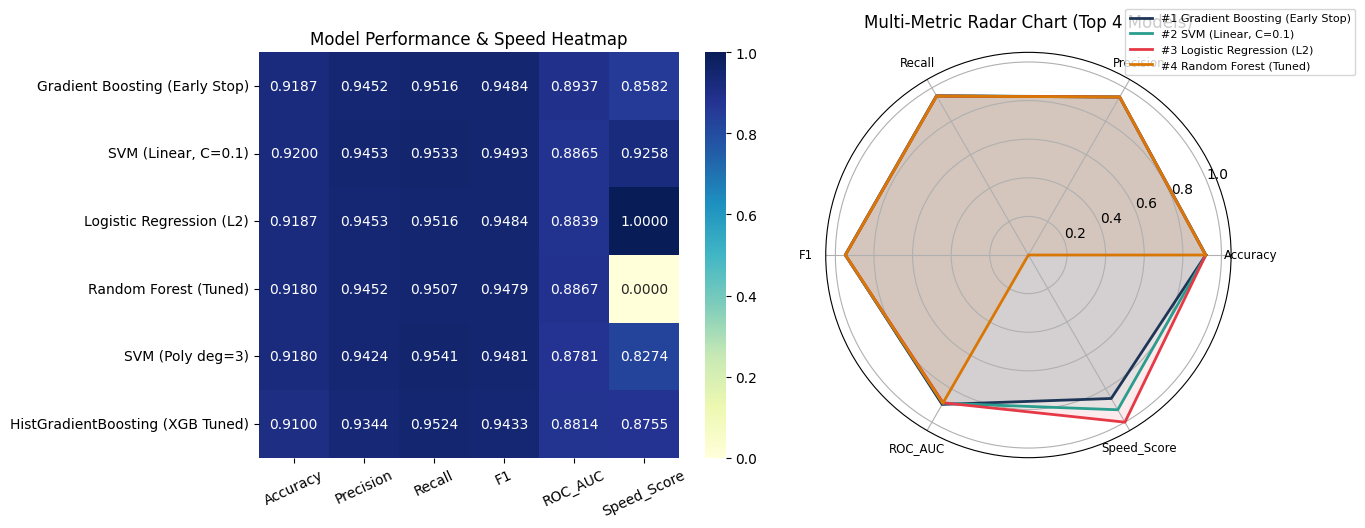

In [90]:
fig = plt.figure(figsize=(14, 5.4))

ax1 = fig.add_subplot(1, 2, 1)
heat_cols = ['Accuracy', 'Precision', 'Recall', 'F1', 'ROC_AUC', 'Speed_Score']
sns.heatmap(
    summary_table.set_index('Model')[heat_cols],
    annot=True, fmt='.4f', cmap='YlGnBu', vmin=0.0, vmax=1.0, ax=ax1
)
ax1.set_title('Model Performance & Speed Heatmap')
ax1.set_ylabel('')
ax1.tick_params(axis='x', rotation=25)

ax2 = fig.add_subplot(1, 2, 2, polar=True)
angles = np.linspace(0, 2 * np.pi, len(heat_cols), endpoint=False).tolist()
angles += angles[:1]

colors = ['#1D3557', '#2A9D8F', '#E63946', '#D97706']
for (_, row), col in zip(summary_table.iloc[:4].iterrows(), colors):
    vals = [row[c] for c in heat_cols] + [row[heat_cols[0]]]
    ax2.plot(angles, vals, linewidth=2.0, label=f"#{int(row['Rank'])} {row['Model']}", color=col)
    ax2.fill(angles, vals, alpha=0.10, color=col)

ax2.set_xticks(angles[:-1])
ax2.set_xticklabels(heat_cols, fontsize=8.5)
ax2.set_ylim(0.0, 1.05)
ax2.set_title('Multi-Metric Radar Chart (Top 4 Models)', pad=18)
ax2.legend(loc='upper right', bbox_to_anchor=(1.32, 1.12), fontsize=8)

plt.tight_layout()
plt.show()

In [91]:
from sklearn.feature_selection import RFE

pipe_rfe_lr = Pipeline([
    ('prep', preprocessor_lr),
    ('rfe', RFE(
        estimator=LogisticRegression(max_iter=1000, random_state=42),
        n_features_to_select=5
    )),
    ('clf', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42))
])

rfe_cv = cross_validate(pipe_rfe_lr, X_lr, y_lr, cv=skf_lr, scoring=['accuracy', 'f1', 'roc_auc'])
print(f"RFE (top 5) + LR -> Acc: {rfe_cv['test_accuracy'].mean():.4f} | F1: {rfe_cv['test_f1'].mean():.4f} | AUC: {rfe_cv['test_roc_auc'].mean():.4f}")

# Inspect selected feature names on full data
pipe_rfe_lr.fit(X_lr, y_lr)
prep_rfe = pipe_rfe_lr.named_steps['prep']
rfe_step = pipe_rfe_lr.named_steps['rfe']
all_names_fs = num_cols + list(prep_rfe.named_transformers_['cat'].get_feature_names_out(cat_cols))
selected_rfe_names = [name for name, keep in zip(all_names_fs, rfe_step.support_) if keep]
print("Selected RFE Features:", selected_rfe_names)

RFE (top 5) + LR -> Acc: 0.9200 | F1: 0.9493 | AUC: 0.8870
Selected RFE Features: ['rating', 'high_rating', 'class_name_Jackets', 'class_name_Skirts', 'class_name_Sweaters']


In [92]:
from sklearn.inspection import permutation_importance

X_fs_proc = preprocessor_lr.fit_transform(X_lr)
if hasattr(X_fs_proc, 'toarray'):
    X_fs_proc = X_fs_proc.toarray()

rf_selector = RandomForestClassifier(
    n_estimators=150, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1
).fit(X_fs_proc, y_lr)

perm_fs = permutation_importance(
    rf_selector, X_fs_proc, y_lr, n_repeats=15, random_state=42, scoring='f1', n_jobs=-1
)
perm_ranked_idx = np.argsort(perm_fs.importances_mean)[::-1]
top_k_perm = 5
top_perm_cols = perm_ranked_idx[:top_k_perm]

print("Top 5 Permutation Features:", [all_names_fs[i] for i in top_perm_cols])

rf_retrained_perm = RandomForestClassifier(
    n_estimators=150, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1
)
perm_cv = cross_validate(
    rf_retrained_perm, X_fs_proc[:, top_perm_cols], y_lr,
    cv=skf_lr, scoring=['accuracy', 'f1', 'roc_auc']
)
print(f"Permutation Top {top_k_perm} + RF -> Acc: {perm_cv['test_accuracy'].mean():.4f} | F1: {perm_cv['test_f1'].mean():.4f} | AUC: {perm_cv['test_roc_auc'].mean():.4f}")

Top 5 Permutation Features: ['rating', 'rating_x_age', 'log_feedback', 'age', 'positive_feedback_count']
Permutation Top 5 + RF -> Acc: 0.9047 | F1: 0.9389 | AUC: 0.8811


PCA (12 comps, 90.9% var) + Logistic Regression -> Acc: 0.9200 | F1: 0.9493 | AUC: 0.8906
PCA (12 comps, 90.9% var) + Random Forest -> Acc: 0.9173 | F1: 0.9475 | AUC: 0.8853


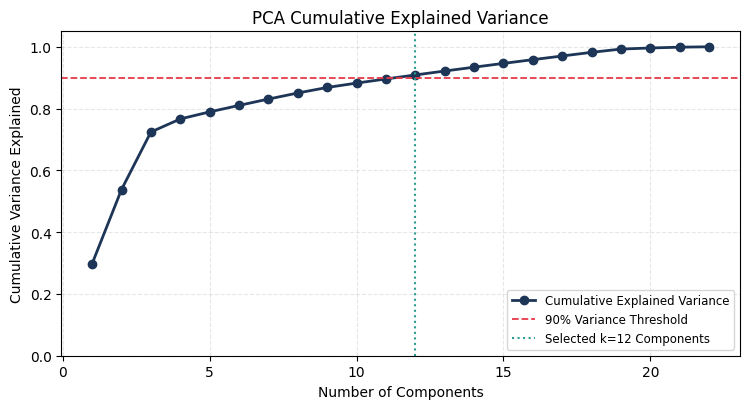

In [93]:
from sklearn.decomposition import PCA

pca_probe = PCA(random_state=42).fit(X_fs_proc)
cum_exp_var = np.cumsum(pca_probe.explained_variance_ratio_)
n_comp_90 = int(np.searchsorted(cum_exp_var, 0.90) + 1)
n_comp_90 = max(2, min(n_comp_90, X_fs_proc.shape[1] - 1))

for m_label, base_clf in [
    ('Logistic Regression', LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=150, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1))
]:
    pca_pipe = Pipeline([
        ('prep', preprocessor_lr),
        ('pca', PCA(n_components=n_comp_90, random_state=42)),
        ('clf', base_clf)
    ])
    pca_cv = cross_validate(pca_pipe, X_lr, y_lr, cv=skf_lr, scoring=['accuracy', 'f1', 'roc_auc'])
    print(f"PCA ({n_comp_90} comps, {cum_exp_var[n_comp_90-1]:.1%} var) + {m_label} -> "
          f"Acc: {pca_cv['test_accuracy'].mean():.4f} | F1: {pca_cv['test_f1'].mean():.4f} | AUC: {pca_cv['test_roc_auc'].mean():.4f}")

fig, ax = plt.subplots(figsize=(7.6, 4.2))
comp_axis = np.arange(1, len(cum_exp_var) + 1)
ax.plot(comp_axis, cum_exp_var, marker='o', linewidth=2.0, color='#1D3557', label='Cumulative Explained Variance')
ax.axhline(0.90, linestyle='--', color='#E63946', linewidth=1.3, label='90% Variance Threshold')
ax.axvline(n_comp_90, linestyle=':', color='#2A9D8F', linewidth=1.5, label=f'Selected k={n_comp_90} Components')
ax.set_title('PCA Cumulative Explained Variance')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Cumulative Variance Explained')
ax.set_ylim(0.0, 1.05)
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(True, linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

In [94]:
X_sh_proc = preprocessor_lr.fit_transform(X_lr)
if hasattr(X_sh_proc, 'toarray'):
    X_sh_proc = X_sh_proc.toarray()

ohe_sh_names = list(preprocessor_lr.named_transformers_['cat'].get_feature_names_out(cat_cols))
sh_feature_names = num_cols + ohe_sh_names

lr_sh = LogisticRegression(penalty='l2', C=1.0, class_weight='balanced', max_iter=1000, random_state=42).fit(X_sh_proc, y_lr)
rf_sh = RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42, n_jobs=-1).fit(X_sh_proc, y_lr)
gb_sh = GradientBoostingClassifier(learning_rate=0.05, max_depth=2, subsample=0.80, n_estimators=80, random_state=42).fit(X_sh_proc, y_lr)

def extract_pos_shap(explainer, X_mat):
    sv = explainer.shap_values(X_mat)
    if isinstance(sv, list):
        return sv[1]
    if getattr(sv, 'ndim', 0) == 3:
        return sv[:, :, 1]
    return sv

shap_lr_pos = extract_pos_shap(shap.LinearExplainer(lr_sh, X_sh_proc), X_sh_proc)
shap_rf_pos = extract_pos_shap(shap.TreeExplainer(rf_sh), X_sh_proc)
shap_gb_pos = extract_pos_shap(shap.TreeExplainer(gb_sh), X_sh_proc)

shap_rf_neg = -shap_rf_pos

global_shap_comp = pd.DataFrame({
    'feature': sh_feature_names,
    'LR_Class1_MeanAbs': np.mean(np.abs(shap_lr_pos), axis=0),
    'RF_Class1_MeanAbs': np.mean(np.abs(shap_rf_pos), axis=0),
    'GB_Class1_MeanAbs': np.mean(np.abs(shap_gb_pos), axis=0),
    'RF_Class0_MeanAbs': np.mean(np.abs(shap_rf_neg), axis=0),
}).sort_values('RF_Class1_MeanAbs', ascending=False)

print("Global SHAP Comparison Across Models & Classes:\n")
print(global_shap_comp.round(4).to_string(index=False))

Background dataset has 1500 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1500 when initializing the masker.


Global SHAP Comparison Across Models & Classes:

                     feature  LR_Class1_MeanAbs  RF_Class1_MeanAbs  GB_Class1_MeanAbs  RF_Class0_MeanAbs
                      rating             0.4614             0.1657             0.6697             0.1657
                 high_rating             1.2409             0.1444             0.6536             0.1444
                rating_x_age             0.0303             0.0402             0.1457             0.0402
                         age             0.0065             0.0205             0.1009             0.0205
division_name_General Petite             0.2120             0.0103             0.0000             0.0103
                log_feedback             0.1580             0.0101             0.0194             0.0101
     positive_feedback_count             0.0681             0.0088             0.0121             0.0088
          class_name_Jackets             0.1533             0.0059             0.0465             0.0059
      

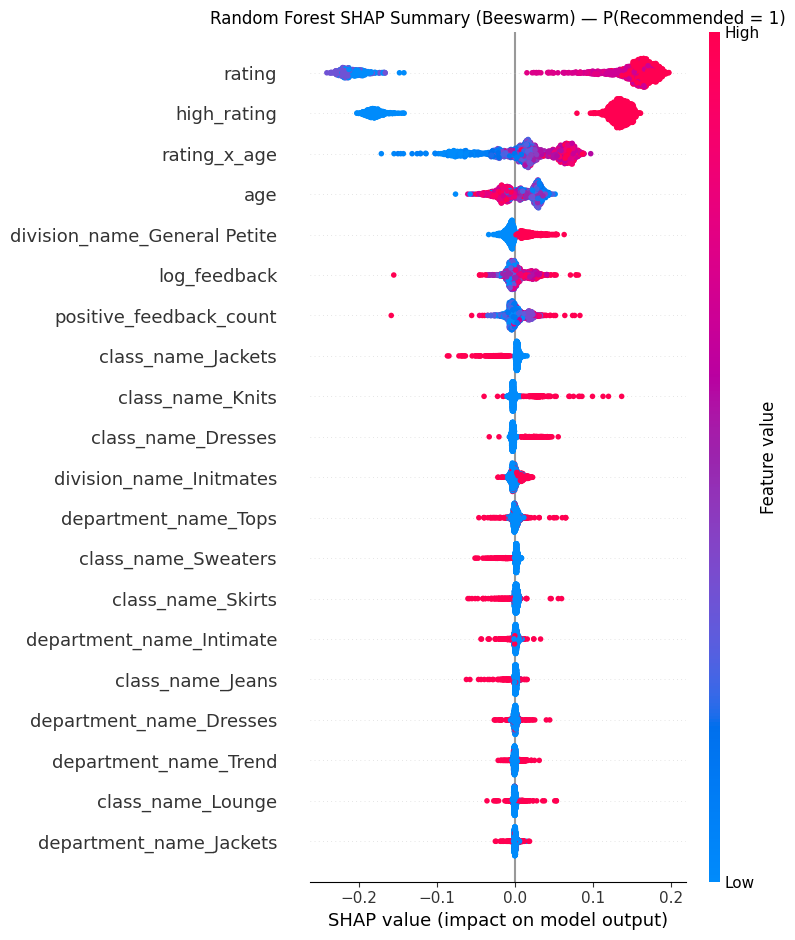

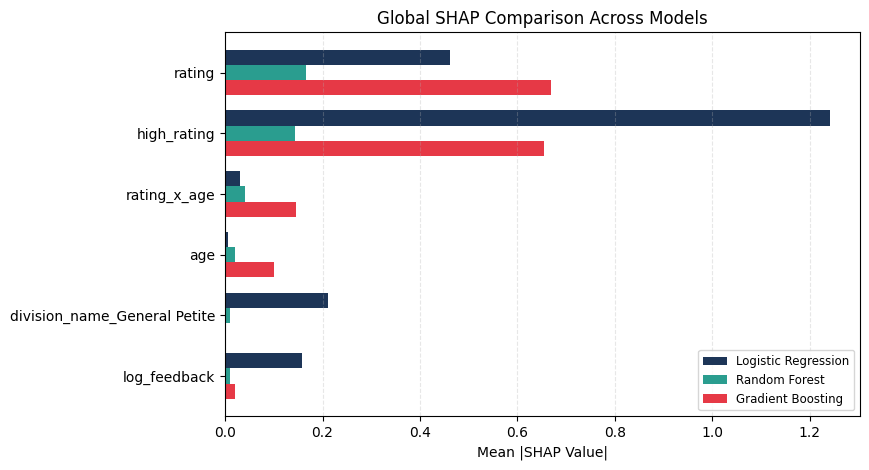

In [95]:
shap.summary_plot(shap_rf_pos, X_sh_proc, feature_names=sh_feature_names, show=False)
plt.title('Random Forest SHAP Summary (Beeswarm) — P(Recommended = 1)')
plt.tight_layout()
plt.show()

top_sh = global_shap_comp.head(6).iloc[::-1]
y_pos = np.arange(len(top_sh))
bar_h = 0.25

fig, ax = plt.subplots(figsize=(8.8, 4.8))
ax.barh(y_pos + bar_h, top_sh['LR_Class1_MeanAbs'], height=bar_h, label='Logistic Regression', color='#1D3557')
ax.barh(y_pos,         top_sh['RF_Class1_MeanAbs'], height=bar_h, label='Random Forest', color='#2A9D8F')
ax.barh(y_pos - bar_h, top_sh['GB_Class1_MeanAbs'], height=bar_h, label='Gradient Boosting', color='#E63946')

ax.set_yticks(y_pos)
ax.set_yticklabels(top_sh['feature'])
ax.set_xlabel('Mean |SHAP Value|')
ax.set_title('Global SHAP Comparison Across Models')
ax.legend(loc='lower right', fontsize=8.5)
ax.grid(axis='x', linestyle='--', alpha=0.3)
plt.tight_layout()
plt.show()

Inspecting Recommended row #0 (Actual y=1)


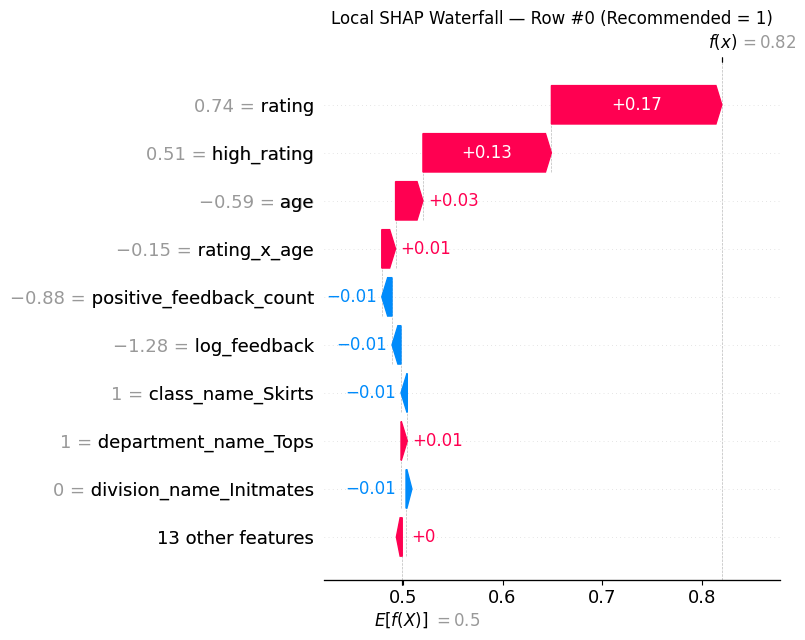

Inspecting Non-Recommended row #1 (Actual y=0)


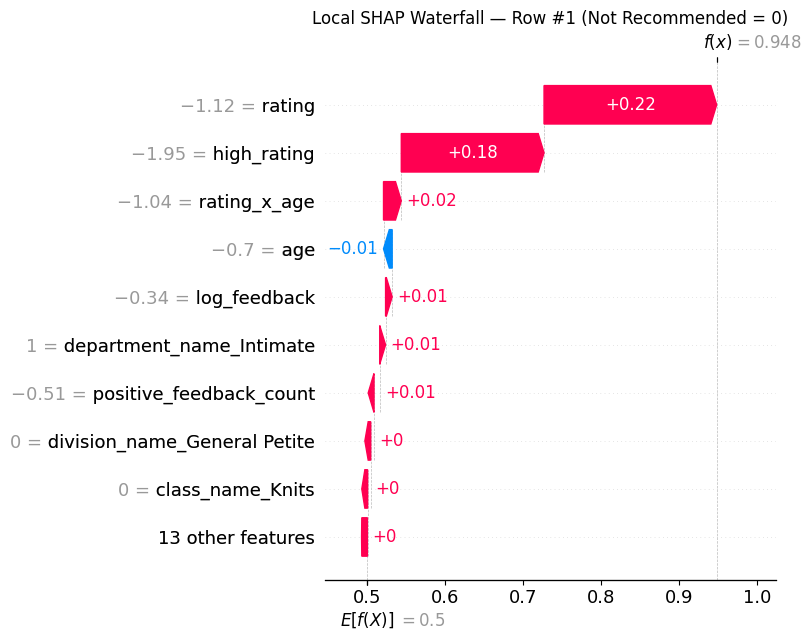

In [96]:
exp_rf = shap.TreeExplainer(rf_sh)
base_val_pos = exp_rf.expected_value[1] if isinstance(exp_rf.expected_value, (list, np.ndarray)) else exp_rf.expected_value

pos_row_idx = int(y_lr[y_lr == 1].index[0])
neg_row_idx = int(y_lr[y_lr == 0].index[0])

print(f"Inspecting Recommended row #{pos_row_idx} (Actual y={y_lr.loc[pos_row_idx]})")
shap.waterfall_plot(
    shap.Explanation(
        values=shap_rf_pos[pos_row_idx],
        base_values=base_val_pos,
        data=np.round(X_sh_proc[pos_row_idx], 2),
        feature_names=sh_feature_names
    ),
    show=False
)
plt.title(f'Local SHAP Waterfall — Row #{pos_row_idx} (Recommended = 1)')
plt.tight_layout()
plt.show()

print(f"Inspecting Non-Recommended row #{neg_row_idx} (Actual y={y_lr.loc[neg_row_idx]})")
shap.waterfall_plot(
    shap.Explanation(
        values=shap_rf_neg[neg_row_idx],
        base_values=1.0 - base_val_pos,
        data=np.round(X_sh_proc[neg_row_idx], 2),
        feature_names=sh_feature_names
    ),
    show=False
)
plt.title(f'Local SHAP Waterfall — Row #{neg_row_idx} (Not Recommended = 0)')
plt.tight_layout()
plt.show()